## Pegasus Evaluation

The evaluation of the paper (Section V). Section A describes the setup, Section B runs the experiments on the coverage
and the tightness of the bounds (B.1 to B.6), and Section C uses the bounds iteratively: fine-tuning with end-to-end
samples (C.1) and choosing a configuration with an optimizer (C.2; its objective is still to be reformulated, see the
note there). Every experiment runs on one of two data sources, chosen with `data_source` in the first code cell:

- **synthetic**: generated service types (`pegasus/data.py`) and the simulator of a chain of queues
  (`pegasus/simulation.py`). A chain never repeats a service type: a seeded generator provides as many different
  service types as the chain is deep.
- **real**: the second testbed campaign in `statics/results_milos_v2/` (the B1 experiments of `new_experiments.md`),
  read by `pegasus/real_data.py`.

**How the real data is used.** Every service of the second campaign takes its items in the order of arrival and gives
each to the first free one of its workers, under Poisson arrivals at a rate that the campaign set for every run. The
latencies that the campaign measured are therefore the ground truth as they are; nothing is emulated. The evaluated
chain is `b1-vision-1-workers` (an object detector, an image transformer and an image compressor with one to four
workers each).

**Held-out runs, not an unseen composition.** The second campaign has one topology per application, and every service
occurs only in that topology, so a service cannot be trained on pipelines of another topology. The runs of the
evaluated chain without throttling (below) are split once (`split_runs` in `pegasus/real_data.py`): `n_pool` runs form
the training pool, from which every seed draws the training runs of B.1, and the other runs are the held-out
configurations, the same under every seed. The models therefore know the topology of the chain, but none of its
held-out runs.

**Only runs without throttling.** Docker enforces the cores of a service as a quota of CPU time per scheduling period
(100 ms by default); a container that has used up its quota stands still until the next period begins (*throttling*;
`throttled_fraction` in `dataset.csv` is the share of the periods of a run in which that happened). An item that is
processed during throttling waits for the next period, a delay that depends on the load and that the execution-time
model of the bounds does not contain. Only the runs in which no service of the chain was throttled are therefore used
(`unthrottled_runs` in `pegasus/real_data.py`); the other runs are neither trained on nor held out. The evaluation thus
covers configurations whose CPU quota suffices for their load.

**Experiments that the real data does not support** are skipped (`skipped` in the first code cell; their cells print
a note and compute nothing): B.3, because every chain of the second campaign has three services; B.4a and B.4b,
because the campaign fixed the Poisson arrival rate of every run, so neither the load nor the arrival pattern can be
changed; C.1, because the held-out runs are too few to provide both the end-to-end samples and a test set; C.2, because it
evaluates every run at one common arrival rate; and the real part of B.2b, which reads the
first campaign. The section of each says the same.

Limits of the real data that hold for every experiment:

- The arrival rate of a run was chosen by the campaign from a short probe, so that the slowest service of the run is
  busy about half of the time; it is therefore not independent of the execution times.
- A service with several workers shares its CPU quota among them, so the execution time of an item is longer while
  other workers are busy (`1_method_real.ipynb`, Section 6f). The bounds assume execution times that do not depend on
  the load.
- A run measured a few hundred to a few thousand requests, so a measured latency quantile far in the tail rests on few
  requests; the confidence interval of every measured quantile accounts for this (`coverage_check`).


In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

import warnings
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.exceptions import ConvergenceWarning

from pegasus.data import (assert_unseen, busiest_utilization, load_chain_data, path_workers, same_configurations, synthetic_chain, with_training_data)
from pegasus.evaluation import (METHOD_COLORS, PROPOSED, PROPOSED_SNC, arrival_text, compare_methods, coverage, finite_share, fit_services,
                                ground_truth_conclusion, sweep_conclusion, sweep_seconds, sweep_statistics, tightness_and_time_figure,
                                tightness_figure, tightness_sweep_figure, time_conclusion)
from pegasus.bounds import martingale_closed_form_node_bound, network_service_bound, propagated_node_bounds, snc_latency_bound
from pegasus.real_data import chain_tail_ratios, split_runs
from pegasus.service_gp import configurations_of

alpha = 0.05                                           # violation probability epsilon: a bound at alpha bounds the (1 - alpha) latency quantile
confidence = 0.95                                      # the pessimistic mean of a bound lies above the true mean with this probability
coverage_check = dict(n_batches=10, confidence=0.95)   # confidence interval of a measured quantile (batch means)
seed = 35                                              # base seed of the data source
seeds = list(range(3))                                 # every experiment is repeated for these seeds; a seed determines the training data and the
                                                       # randomness of the ground truth, and with synthetic data also the generated service types
n_calibration = 20                                     # training configurations that Conformal sets aside for calibration; the rest trains its model
p_label = f"p{100 * (1 - alpha):g}"
pegasus_versions = [PROPOSED, PROPOSED_SNC]            # the two versions of the proposed method: union bound over node bounds, network service curve
competitors = [name for name in METHOD_COLORS if name != "Oracle"]   # the proposed method and the baselines; the Oracle is a reference
# B.2 to B.6 keep one of the two execution-time baselines. GP Sum stays, because it is the faster one: it uses the GPs that
# Pegasus and Kingman train anyway, while DNN Sum needs a network trained per service.
only_base_case = ("DNN Sum",)
sweep_competitors = [name for name in competitors if name not in only_base_case]  # the methods of B.2 to B.6 without the Oracle

# What differs between the two data sources: which chain an experiment uses, and which loads and depths exist
if data_source == "synthetic":
    chain_options = lambda s: dict(path=synthetic_chain(3), service_seed=s)               # the chain of B.1 under the seed s
    depth_options = lambda depth, s: dict(path=synthetic_chain(depth), service_seed=s)    # B.3: the chain of a depth
    training_options = lambda s: dict(service_seed=s)                                     # B.2: what with_training_data needs besides the data
    depths = [1, 2, 5, 10, 20, 50]
    load_option, loads = "arrival_rate", [1, 2, 3, 4, 5]                                  # B.4a: arrival rate (items/s) of all configurations
    load_label = lambda load: f"{load:g}/s"
    base_options = {}                                                                     # B.1: the default number of training configurations
else:
    base_experiment = "b1-vision-1-workers"                                               # the chain of B.1: detector -> transformer -> compressor, 1 to 4 workers each
    n_pool = 35                                                                           # unthrottled runs of the chain that may train the models; the other unthrottled runs are held out
    base_split = split_runs(base_experiment, n_pool, seed, unthrottled=True)              # (training pool, held-out runs), the same under every seed
    base_options = dict(n_train=30)                                                       # B.1: training runs per service and seed, drawn from the pool
    chain_options = lambda s: dict(experiment=base_experiment, split=base_split)
    training_options = lambda s: dict(level=1 - alpha, coverage_check=coverage_check, **chain_options(s))

# Experiments that the data source does not support; their cells do nothing (the section of each says why). The real part
# of B.2b uses the first campaign, so it is skipped with either source.
skipped = {"B.2b real"} if data_source == "synthetic" else {"B.2b real", "B.3", "B.4a", "B.4b", "C.1", "C.2"}


def chain_data(s, **changes):
    # Data of the chain of B.1 under the seed s; `changes` replace options of the loader of the data source
    return load_chain_data(data_source, **{**dict(level=1 - alpha, coverage_check=coverage_check, seed=[seed, s]), **chain_options(s), **base_options, **changes})

## A. Experimental Setup

### Services and Chains

- **Synthetic:** `synthetic_service` in `pegasus/data.py` generates every service type from the seed
  `service_seed`: an execution-time function and a noise level with randomly drawn parameters. A chain of depth K
  consists of the first K service types (`synthetic_chain`), so no service type occurs twice in a chain. All services
  of a chain share one configuration (CPU, quality, parallelism).
- **Real:** the three services of the chain `b1-vision-1-workers`, each with its own knobs (cores, workers and the
  knobs of the application: the resolution, and the model size of the object detector). A run of the campaign is one
  configuration of every service of the chain, drawn at random.

### Sampling Strategies

- **Synthetic:** training and held-out configurations are drawn uniformly at random. Active learning and grid search
  are possible, but not implemented.
- **Real:** the campaign drew the configuration of every run at random. The training runs are drawn at random from
  the training pool of the chain (see the introduction); the held-out configurations are the other runs.

### Baselines

Every baseline is trained on data of each service on its own, like the proposed method; none sees a held-out run. All are in `pegasus/baselines.py`, and B.1 describes them (Methods).

- Execution-time model per service, summed, without queue (GP, DNN).
- Queueing formula per service, summed (Kingman).
- Latency quantile per service with split budget, without and with a conformal step (Quantile Union, Conformal). These
  two need every service monitored alone under load. With synthetic data, the simulator provides such runs; with real
  data, they are the latencies that a training run measured at the service inside the chain.

## B. Coverage and Tightness of Service Bounds

### B.1 Base Case

- **Synthetic:** the chain $s_1 \to s_2 \to s_3$ of three generated service types.
- **Real:** the chain detector → transformer → compressor (`base_experiment`, `b1-vision-1-workers`): an object
  detector, an image transformer and an image compressor, each with one to four workers.
- **Baselines:** the three per-service categories of A (execution-time model summed, with GP and DNN; queueing formula per
  service; latency quantile per service with split budget, without and with a conformal step), and the union bound over measured nodes as reference.

**Setting (synthetic data).** The chain $s_1 \to s_2 \to s_3$ with every service at the same configuration, at held-out configurations
drawn from the training range; no held-out configuration occurs in the training data of any model. The ground truth
is the measured $(1-\varepsilon)$ quantile of the end-to-end latency of the chain, with $\varepsilon$ = `alpha`. The
experiment is repeated for every seed in `seeds`: a seed determines the three generated service types, the training
data and the held-out configurations. The figures pool the held-out configurations of all seeds; whether a method
holds is judged per seed (see Metrics).

**Setting (real data).** The held-out configurations are the held-out runs of the chain (see the introduction): every
run is one configuration of each of the three services, at the Poisson arrival rate that the campaign set for it. The
ground truth is the $(1-\varepsilon)$ quantile of the end-to-end latencies that the run measured. The chain and its
held-out runs are the same under every seed; a seed determines the training runs.

**Dependence between services.** The execution time of an item at one service can depend on its execution time at
another service of the chain: a large item is slow everywhere. The two data sources differ in this.
- *Synthetic:* the execution times of an item at the different services are independent. The simulator draws the
  execution-time noise of every service on its own (`item_correlation` = 0 in `pegasus/data.py`), so an item that is
  slow at one service is not more likely to be slow at the next one. `1_method_synthetic.ipynb` sets a positive
  `item_correlation` instead, to show the compositions under dependence.
- *Real:* the measured requests keep any dependence between the services that the testbed had.

With both sources, the latencies of an item at consecutive services depend on each other through the queues. Pegasus
per node is valid for any dependence between the services. Pegasus SNC assumes that the execution times of an item
are independent between the services (see Methods): that holds for the synthetic data and is an assumption for the
real data, which the coverage of Pegasus SNC tests but cannot prove. This holds in every experiment of B.

**Training data (real data).** The training runs are drawn at random from the training pool of the chain; a held-out
run is never used. A training run gives every service one training configuration, and two statistics of its measured
execution times (processing time plus the handling overhead of the run, `1_method_real.ipynb`, Section 1a) as targets:
- the *mean* of the run, in seconds. A model of the execution time is trained on these run means and not on one item
  per run: a run measured many items, and their mean is a far less noisy observation of the mean execution time than
  one item. The error of the predicted mean is what makes the queueing-based methods fail
  (`explain_5_what_kingman_inputs_cost.ipynb` measures this on the Kingman baseline).
  The GP is fitted on the logarithm of the run means: the knobs of a real service multiply its processing time (a
  larger model at a higher resolution with more workers), and on the logarithm these effects add, which a GP with one
  length scale per knob can fit. The length scale of every GP on real data has a lower limit (`MIN_LENGTH_SCALE` in
  `pegasus/service_gp.py`, in standard deviations of a knob): without it, the hyperparameter search of some services
  ends at a length scale near zero, where the GP reproduces every training run and predicts the average of all runs
  everywhere else (`1_method_real.ipynb`, Section 3, shows the fitted surfaces).
- the *spread* of the run, in seconds: (95th percentile − median of the processing time) ÷ 1.645, the standard
  deviation of a Gaussian with that median and 95th percentile. A second GP per service is trained on the logarithm of
  the spreads and predicts the standard deviation of single items, which one item per run would otherwise have told
  the model.

With these two models, the belief of Pegasus about a service is: the pessimistic mean is the predicted mean shifted up
by the GP's uncertainty about the mean of a new run (its uncertainty about the mean function and the scatter between
runs at the same configuration; on the logarithm, so the shift is relative to the mean), and the variance per item is
the square of the predicted spread. GP Sum, DNN Sum and
Kingman use the predicted mean and the predicted spread. With synthetic data nothing changes: one execution time per
training configuration, and one GP for both.

For Quantile Union and Conformal, a service is monitored by the
latencies that a training run measured at it inside the chain, at the arrival rate of that run. Because that rate
differs between runs, the two baselines get the arrival rate as a further input. Their GPs are fitted on the logarithm of the latency quantile,
for the same reason as the GP of the mean execution time.

**Training data (synthetic data).** Every method is trained on data of each service on its own and never on a run of the chain. The
proposed method, the two execution-time baselines and the queueing formula use one execution time per service and training configuration.
Quantile Union and Conformal use the latencies (waiting plus execution) of each service monitored alone under the
arrival process of the workload, at the same training configurations.

**Metrics.** *Tightness* of a method at a configuration is its end-to-end latency ÷ the measured quantile: 1 is exact,
above 1 is looser, below 1 is under the measured quantile. *Coverage* is the share of configurations at which a method
is not below the lower edge of the confidence interval of the measured quantile (`coverage_check`).

*Training time* and *evaluation time* of a method, both in seconds on the machine that ran the notebook, are reported
in B.2 and B.3.
- The training time is the time to train the models that the method uses. Both versions of Pegasus, GP Sum and Kingman
  use the same execution-time GPs, one per service, so these four methods have the same training time. Quantile Union
  and Conformal each train their own GPs of the latency quantile, one per service; for Conformal the calibration of the
  correction factor counts as training.
- The evaluation time is the time to compute the end-to-end latency at all held-out configurations of one seed from the
  trained models, including the predictions of these models.
- Neither time contains the collection of the training data: one execution time per service and training configuration
  for the four methods on execution-time GPs, and a run under load per service and training configuration for Quantile
  Union and Conformal.

**Validity before tightness.** This rule is the same in every experiment of B.
- A method *reaches the confidence level* under a seed if its coverage over the held-out configurations of that seed
  is at least `confidence`.
- A method *holds* in a setting if it reaches the confidence level under every seed in `seeds`. A setting is the base
  case here and one value of the varied quantity in B.2 to B.6, for example one number of training configurations in
  B.2 or one depth in B.3. The worst seed decides: a method with
  full coverage under all seeds but one that falls below `confidence` under the remaining seed does not hold, because
  a guarantee that depends on the drawn services and training data is not a guarantee.
- Every conclusion first names the methods that hold, and compares tightness only among those. The tightness of a
  method that does not hold describes a value that can lie below the measured quantile, not a bound.

**Methods.** The proposed method has two versions. Both use the same GP model of the execution time per service and
differ in how the services are composed; `explain_3_how_pegasus_bounds_compose.ipynb` derives both and tests their strengths
and weaknesses.
- *Pegasus per node (ours):* the union bound over martingale node bounds in closed form. The waiting time at a service is
  bounded by Kingman's martingale bound, an exponential tail whose rate follows from the moment generating function of
  the service's execution time and from its arrivals; with a Gaussian execution time, the latency bound of the service
  is then one formula. The first service receives the external arrivals, and every later service the departures of
  the service before it, which cannot be closer together than that service's execution times. Every service is bounded
  at the violation probability $\varepsilon / K$ for a chain of $K$ services, and the $K$ bounds are added; this is valid
  for any dependence between the services.
- *Pegasus SNC (ours):* one bound for the whole chain from its network service curve (stochastic network calculus, SNC).
  The latency moments of the services (the moment generating function of the execution time ÷ (1 − utilization at that
  parameter θ)) are multiplied, and one Chernoff step on the product bounds the end-to-end latency at the full
  violation probability $\varepsilon$. Multiplying the moments requires independent services (see Dependence between
  services). No Hölder step is applied: it would make the bound valid for dependent services, at the price of a larger
  variance per service and of a longer evaluation, because its exponents are tuned iteratively for every configuration
  and every θ; the ablation below shows the bound with that step. Only the external arrivals enter this bound; the
  minimum spacing between the departures of a service, which the per-node version uses, is not exploited.
- *GP Sum, DNN Sum (baselines; execution-time model per service, summed, no queue):* the $(1-\varepsilon)$ quantile of the sum of the
  predicted execution times, with a GP and with a neural network (DNN) per service. Both are compared here; B.2 to B.6
  keep GP Sum only (`only_base_case`), the faster of the two, because the GPs are trained for Pegasus and Kingman anyway.
- *Kingman (baseline; queueing formula per service, summed):* the GP's mean and variance of the execution time enter a textbook
  formula for one queue (Kingman's approximation of the mean waiting time, an exponential waiting-time tail), which
  gives the $(1-\varepsilon)$ latency quantile of each service; the quantiles are added.
- *Quantile Union (baseline; latency quantile per service, split budget):* one GP per service predicts the
  $(1-\varepsilon/K)$ latency quantile of the service alone under load, for a chain of $K$ services; the predictions
  are added. This is the union bound applied to point predictions, trained on all training configurations.
  *Note:* the arrival rate is not an input of this model, so the model holds only for the workload its services were
  monitored under. With the arrival rate as an input (as in Fluxion), samples from existing executions at other loads
  could be reused for a new composition. The model would still not know that later services of a chain queue less:
  every service of a chain receives the same rate, and what changes is how evenly the arrivals are spaced.
- *Conformal (baseline; Quantile Union with a conformal step):* the same model, trained on the training
  configurations except `n_calibration` of them, on which a correction factor is calibrated (the ratio measured ÷
  predicted quantile). Every prediction is multiplied by that factor, so that it holds per service with probability
  `confidence`; the bounds of the services are added.
- *Oracle (reference):* the union bound over the measured latency quantiles of the services in the chain; it uses the ground
  truth and is not a competitor. With real data it reads them from the first requests of every run, as many as the
  shortest held-out run has.

In [2]:
# Data of the chain and the per-service models for every seed; no model sees a run of the evaluated chain
bases, base_models = {}, {}
with warnings.catch_warnings():
    # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for s in seeds:
        bases[s] = chain_data(s)
        assert_unseen(bases[s])
        base_models[s] = fit_services(bases[s], bases[s].x_train, bases[s].y_train, model_seed=seed + s, confidence=confidence)
base = bases[seeds[0]]   # for what is the same under every seed: the names in the chain, the workload, the numbers of configurations
K, workload = len(base.path), base.workload
n_train = len(configurations_of(base.x_train, base.path[0]))   # training configurations per service
arrivals = arrival_text(workload)
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

real data, 3 seeds: chain detector -> transformer -> compressor, per seed 30 training configurations per service and 18 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 107/s)


In [3]:
def base_case(s):
    """Every method, and every composition of the ablation, for the chain of the seed s: two dictionaries
    name -> (group, end-to-end latency per held-out configuration in s)."""
    data, models = bases[s], base_models[s]
    methods, _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration, model_seed=seed + s,
                                 x_train_load=data.x_train_load)
    workload = data.workload
    beliefs, lower_means, workers = models["beliefs"], models["lower_means"], path_workers(data)   # workers of every service per configuration
    # Ablation: the other ways to bound the nodes and to compose them, all on the same GP beliefs
    compositions = {
        "union bound, Chernoff (SNC) nodes": ("proposed", sum(snc_latency_bound(*b, epsilon=alpha / K, workers=w, **workload) for b, w in zip(beliefs, workers))),
        "union bound, propagated Chernoff (SNC) nodes": ("proposed", propagated_node_bounds(beliefs, epsilon=alpha / K, path_lower_means=lower_means,
                                                                                            path_workers=workers, **workload).sum(axis=0)),
        "union bound, martingale nodes": ("proposed", sum(martingale_closed_form_node_bound(*b, epsilon=alpha / K, workers=w, **workload)
                                                          for b, w in zip(beliefs, workers))),
        "union bound, propagated martingale nodes = Pegasus per node": ("proposed", methods[PROPOSED][1]),
        "network service curve, independent services = Pegasus SNC": ("proposed", methods[PROPOSED_SNC][1]),
        "network service curve, Hölder (any dependence)": ("proposed", network_service_bound(beliefs, epsilon=alpha, path_workers=workers, **workload)),
    }
    return methods, compositions


def pooled(results):
    """One dictionary name -> (group, latencies) from one per seed: the held-out configurations of all seeds, one seed after the other."""
    return {name: (results[0][name][0], np.concatenate([result[name][1] for result in results])) for name in results[0]}


def seeds_reached(results):
    """Number of seeds under which a method reaches the confidence level, name -> count, from one dictionary per seed."""
    return {name: sum(coverage(result[name][1], bases[s].measured_low) >= confidence for s, result in zip(seeds, results)) for name in results[0]}


per_seed = [base_case(s) for s in seeds]
methods, compositions = pooled([m for m, _ in per_seed]), pooled([c for _, c in per_seed])
methods_reached, compositions_reached = seeds_reached([m for m, _ in per_seed]), seeds_reached([c for _, c in per_seed])
# the ground truth of all seeds in the same order as the pooled latencies
base_pooled = SimpleNamespace(path=base.path, workload=workload, measured=np.concatenate([bases[s].measured for s in seeds]),
                              measured_low=np.concatenate([bases[s].measured_low for s in seeds]))
print(f"{len(methods)} methods and {len(compositions)} compositions computed for {len(seeds)} seeds.")

8 methods and 6 compositions computed for 3 seeds.


**Figures.** Both figures have one row per method and show its tightness over the held-out configurations on a
logarithmic axis (box: quartiles, line: median, whiskers and points: the remaining configurations; configurations
without a finite latency are left out). The vertical line at 1× is the measured quantile: a value to the left of
that line is below the measured quantile. The tightness axis of every figure in B covers 0.2× to 64×; a method that lies
outside that range at some configuration or setting is cut off at the edge of the axis. The column "seeds" right of the rows gives the number of seeds under which
the method reaches the confidence level. A filled box is a method that holds, i.e. reaches the level under every seed;
a hatched box is a method that does not hold. Look at the hatching first and compare the position of the boxes only
among the filled ones. The first figure compares the two versions of the proposed method with the
baselines. The second is an ablation: every way to bound the nodes and to compose them on the same GP models. Its rows
name the two versions of Pegasus. The first four rows add one bound per service (union bound); the last two bound the
whole chain with its network service curve, without the Hölder step (Pegasus SNC) and with it. With the step the bound
also holds for dependent services; without it, it is a guarantee only if the execution times of an item are
independent between the services, which holds for the synthetic data and is not known for the real data (see
Dependence between services). The difference between the last two rows is what the Hölder step costs in tightness.

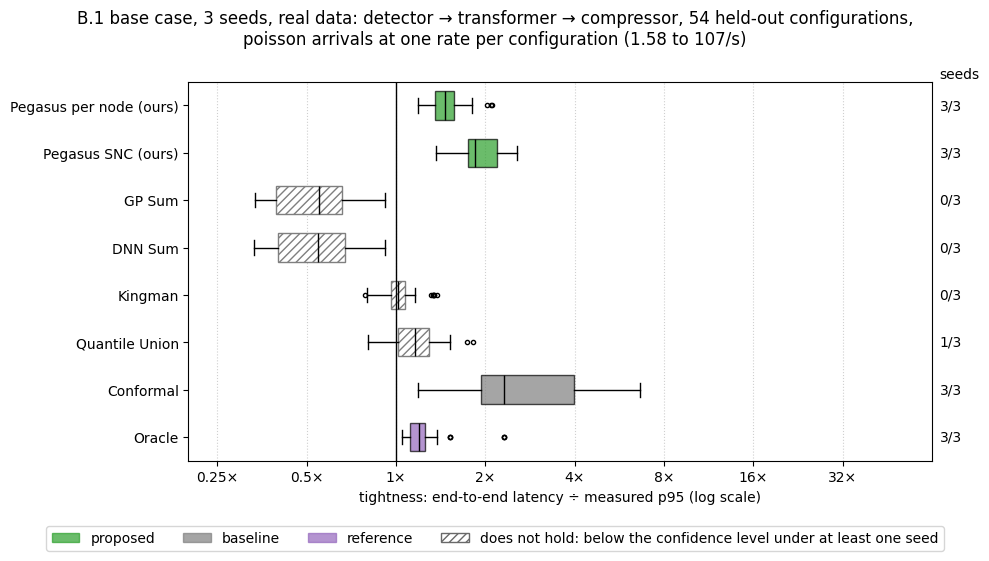

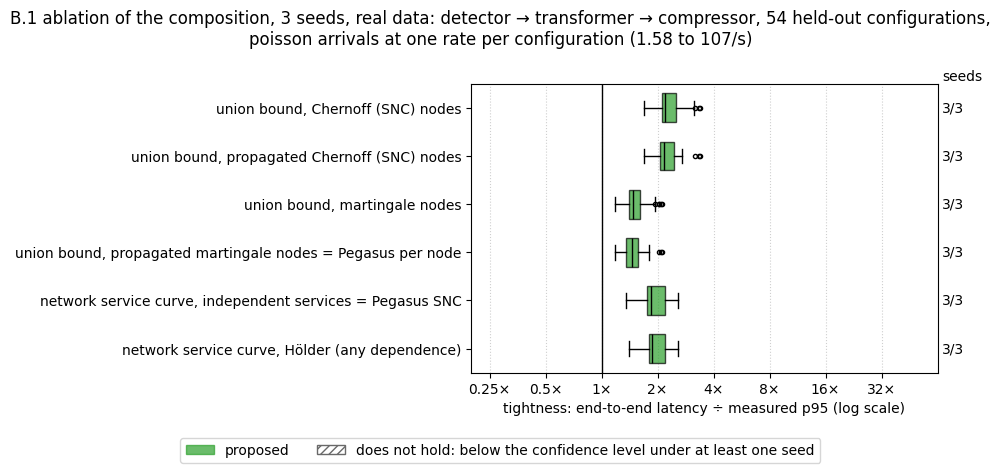

In [4]:
tightness_figure(methods, base_pooled, f"B.1 base case, {len(seeds)} seeds, {data_source} data", p_label, methods_reached, len(seeds))
tightness_figure(compositions, base_pooled, f"B.1 ablation of the composition, {len(seeds)} seeds, {data_source} data", p_label, compositions_reached, len(seeds))

In [5]:
base_tightness = lambda name: np.median(methods[name][1] / base_pooled.measured)   # median over the held-out configurations of all seeds
base_finite = lambda name: np.mean(np.isfinite(methods[name][1]))                  # share of the held-out configurations with a finite latency
base_holding = [name for name in competitors if name in methods and methods_reached[name] == len(seeds)]
base_failing = [name for name in competitors if name in methods and methods_reached[name] < len(seeds)]
guaranteed = [name for name, (group, _) in compositions.items() if group == "proposed"]
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    f"- **Validity.** Methods that hold, i.e. reach the confidence level under every seed: {', '.join(base_holding) or 'none'}. "
    f"Methods that do not hold: "
    + (", ".join(f"{name} (reaches it under {methods_reached[name]} of {len(seeds)} seeds)" for name in base_failing) or "none")
    + ".\n"
    f"- **Tightness among the methods that hold** (median over the held-out configurations of all seeds; in brackets the share of these "
    f"configurations at which the method gives a finite latency): "
    + (", ".join(f"{name} {base_tightness(name):.2f}× ({base_finite(name):.0%})" for name in sorted(base_holding, key=base_tightness)) or "no method holds")
    + ". A configuration without a finite latency counts as covered, but the method says nothing there.\n"
    f"- **Ablation.** {sum(compositions_reached[name] == len(seeds) for name in guaranteed)} of the {len(guaranteed)} compositions with a guarantee hold."
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 107/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold: GP Sum (reaches it under 0 of 3 seeds), DNN Sum (reaches it under 0 of 3 seeds), Kingman (reaches it under 0 of 3 seeds), Quantile Union (reaches it under 1 of 3 seeds).
- **Tightness among the methods that hold** (median over the held-out configurations of all seeds; in brackets the share of these configurations at which the method gives a finite latency): Pegasus per node (ours) 1.46× (100%), Pegasus SNC (ours) 1.84× (100%), Conformal 2.32× (100%). A configuration without a finite latency counts as covered, but the method says nothing there.
- **Ablation.** 6 of the 6 compositions with a guarantee hold.

**Why Kingman does not hold.** The Kingman baseline is the tightest method that uses execution times only.
`explain_5_what_kingman_inputs_cost.ipynb` repeats its queueing formula with the true and with the pessimistic mean and
variance of the execution time, on the chain, the held-out configurations and the models of B.1, and shows which input
the misses come from and what a margin on the mean costs.

### B.2 Varying Evidence per Service

- **Synthetic:** by varying the number of training configurations per service. The simulator cannot test the
  transfer between compositions, because a service's execution time does not depend on the chain there.
- **Real:** by varying the number of training runs, drawn from the training pool of the chain (see Training data in
  B.1); the largest number is the whole pool. A training configuration is one run with its mean and its
  spread, so more evidence means more runs, not more items per run.
- **Baselines:** as in B.1 without DNN Sum (see Methods in B.1), each with the same training data as the
  proposed method.


**Setting.** For every seed, the chain, the held-out configurations and the ground truth of B.1. Only the
training data changes: `evidence_sizes` training configurations per service, drawn anew for every size
and seed. With real data, a training configuration is one *training run* of a service: the figure and the conclusion
count training runs. They are drawn from the training pool of the chain and never from its held-out runs. With synthetic data,
no held-out configuration occurs in any of them. Conformal sets aside the same share of its configurations
for calibration as in B.1, and at least 19, the fewest that give it a finite bound; it is left out where fewer than 5
configurations would remain to train its model. The Oracle uses no training data.

**Complexity (against the amount of training data).** Training time and evaluation time are defined in B.1
(Metrics). With $n$ training configurations per service, training a GP costs on the order of $n^3$ operations per step
of its hyperparameter search, because every step factorizes an $n \times n$ matrix; the training time of every method
is therefore expected to grow with $n$, and faster than linearly for large $n$. A prediction of a trained GP at one
held-out configuration costs on the order of $n$ operations for the mean and $n^2$ for the variance. The evaluation
time contains these predictions and the computation of the bound from them, which does not depend on $n$; the
evaluation time is therefore expected to stay far below the training time, and to grow with $n$ only for the methods
whose evaluation consists mostly of GP predictions. The complexity against the depth
of the chain is analyzed in B.3.

**Figure.** Three panels with the number of training configurations per service on the horizontal axis (logarithmic).
*Left:* tightness, for every seed the median over its held-out configurations; the horizontal line at 1× is the
measured quantile, and a value under that line is below the measured quantile. *Middle:* training time (s,
logarithmic), one line per set of trained models; the legend inside the panel names the methods that use these models.
*Right:* evaluation time (s, logarithmic), one line per method. Every line is the median over the seeds, and the band
around it reaches from the smallest to the largest seed. In the left panel a filled marker means that the method holds
at that number of training configurations (it reaches the confidence level under every seed, as defined in B.1), and a
hollow marker that it does not. Conformal has no point where it is left out. Look at the markers first: only lines
with filled markers are bounds whose tightness can be compared.

In [6]:
# B.2: the chains of B.1 with training data of different sizes
evidence_sizes = [10, 15, 25, n_pool] if data_source == "real" else [10, 15, 25, 50, 100, 200]   # training configurations per service; real: at most the pool
calibration_share = n_calibration / n_train             # share that Conformal sets aside for calibration, as in B.1
evidence, evidence_seconds = {}, {}                     # (size, seed) -> name -> (group, latency per held-out configuration) / (training time, evaluation time) in s
with warnings.catch_warnings():
    # with few training configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for size in evidence_sizes:
        for s in seeds:
            data = with_training_data(data_source, bases[s], n_train=size, seed=[seed, s, size], **training_options(s))
            assert_unseen(data)
            models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
            evidence[(size, s)], evidence_seconds[(size, s)] = compare_methods(
                data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration=max(19, round(calibration_share * size)),
                model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
print(f"{len(evidence)} training sets evaluated.")

12 training sets evaluated.


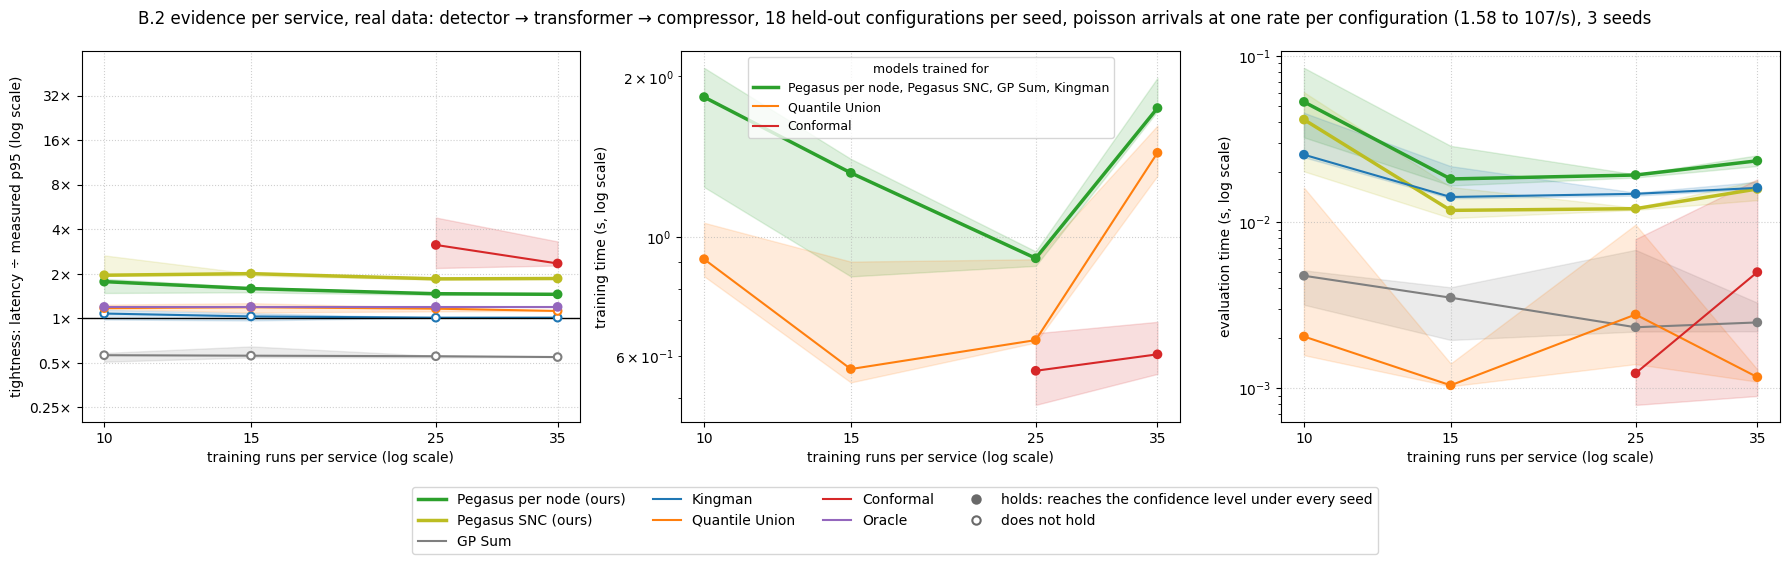

In [7]:
# B.2: coverage, tightness and times per number of training configurations; the ground truth is that of B.1 at every number
# with real data a training configuration is one run of a service, with the mean and the spread of its processing times
training_unit = "training runs" if data_source == "real" else "training configurations"
evidence_truth = {(size, s): (bases[s].measured, bases[s].measured_low) for size in evidence_sizes for s in seeds}
evidence_statistics = sweep_statistics(evidence, evidence_truth, evidence_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
evidence_times = sweep_seconds(evidence_seconds, evidence_sizes, seeds)                                # name -> training, evaluation
tightness_and_time_figure(evidence_sizes, evidence_statistics, evidence_times, f"{training_unit} per service (log scale)",
                          f"B.2 evidence per service, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed, "
                          f"{arrivals}, {len(seeds)} seeds", p_label)

In [8]:
size_label = lambda size: f"{size} {training_unit}"
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(evidence_sizes, evidence_statistics, sweep_competitors, size_label) + "\n"
    + time_conclusion(evidence_sizes, evidence_times, sweep_competitors, size_label)
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 107/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where: GP Sum at every setting; Kingman at every setting; Quantile Union at every setting. Conformal is not computed at 10 training runs, 15 training runs.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 1.77× at 10 training runs to 1.45× at 35 training runs; Pegasus SNC (ours) from 1.96× at 10 training runs to 1.86× at 35 training runs; Conformal from 3.13× at 25 training runs to 2.35× at 35 training runs.
- **Training time** (median over the seeds; methods that share their models are named together): Pegasus per node (ours), Pegasus SNC (ours), GP Sum, Kingman 1.8 s at 10 training runs and 1.7 s at 35 training runs; Quantile Union 0.91 s at 10 training runs and 1.4 s at 35 training runs; Conformal 0.56 s at 25 training runs and 0.6 s at 35 training runs.
- **Evaluation time** (median over the seeds): Pegasus per node (ours) 0.053 s at 10 training runs and 0.023 s at 35 training runs; Pegasus SNC (ours) 0.041 s at 10 training runs and 0.016 s at 35 training runs; GP Sum 0.0048 s at 10 training runs and 0.0025 s at 35 training runs; Kingman 0.025 s at 10 training runs and 0.016 s at 35 training runs; Quantile Union 0.002 s at 10 training runs and 0.0012 s at 35 training runs; Conformal 0.0012 s at 25 training runs and 0.005 s at 35 training runs.

#### B.2b Choosing the Next Configuration

**Question.** B.2 draws the training configurations at random. Does the bound become valid and tight with fewer
benchmarks if the next configuration is chosen with what the models already know?

- **Synthetic:** run first, whatever `data_source` is set to: only the synthetic system can be benchmarked at any
  configuration.
- **Real:** skipped. It selects among the runs of the first campaign (`real_exploration_results` in
  `pegasus/exploration.py`), which this notebook no longer evaluates; the description below is kept for a later port
  to the second campaign.
- **Method evaluated:** Pegasus per node. The baselines that need a service monitored under load are left out, because
  they would need a strategy of their own for their latency models.

**Setting (synthetic data).** The chain, the held-out configurations and the ground truth of the synthetic B.1, for every seed. A
*benchmark* of a configuration measures one execution time of every service at that configuration (all services of a
synthetic chain share one configuration). A *sampling strategy* decides which configuration is benchmarked next. Every
strategy benchmarks `explore_sizes[-1]` configurations one after the other; after $n$ benchmarks, the models are fitted
to the first $n$ configurations as in B.2, and the bound is computed at the held-out configurations.

**Strategies (`pegasus/exploration.py`).** Two do not look at the models:
- *Random:* every configuration is drawn uniformly at random, as in B.2.
- *Sobol sequence:* the first points of a scrambled Sobol sequence, which fills the space more evenly than random
  draws.

Four are adaptive. They start from `n_initial` random configurations, the same for all four. Before every further
benchmark, one GP per service is fitted to the configurations benchmarked so far, an *acquisition function* gives every
candidate configuration a score, and the candidate with the largest score is benchmarked. The candidates are a fixed
set of random configurations. With $m_k(x)$ the predicted mean execution time (s) of service $k$ at the configuration
$x$ and $\sigma_k^2(x)$ the variance of that mean (the GP's uncertainty about the mean, without the scatter of single
items):
- *Maximum variance* (uncertainty sampling): the score is $\sum_k \sigma_k^2(x)$. It benchmarks where the models know
  least, which is often at the edge of the space.
- *Variance reduction:* the score is how much a benchmark at $x$ would reduce the variance of the mean at a set of
  reference configurations spread over the space, summed over the services. Unlike maximum variance, it counts what a
  benchmark tells about the rest of the space.
- *Upper confidence bound:* the score is $\sum_k m_k(x) + 2\sqrt{\sum_k \sigma_k^2(x)}$, the predicted total
  execution time of the chain plus two standard deviations. It benchmarks configurations that are slow or uncertain,
  where the queues are longest.
- *Expected improvement:* the score is the expected amount by which the total execution time at $x$ falls below the
  smallest total measured so far. It is the acquisition function of Bayesian optimization for finding the fastest
  configuration, and is included to show what a strategy does that searches for an optimum instead of learning the
  whole space.

**Figure.** Both panels have the number of benchmarked configurations on the horizontal axis (logarithmic) and one line
per strategy: the median over the seeds, with a band from the smallest to the largest seed. *Left:* the tightness of
Pegasus per node, for every seed the median over its held-out configurations; a filled marker means that the bound
holds with the configurations of that strategy (it reaches the confidence level under every seed, as defined in B.1), a
hollow marker that it does not. *Right:* the error of the predicted mean execution time in percent: the median over
the held-out configurations and the services of |predicted mean ÷ true mean − 1|. Look first at which strategies have
filled markers with few benchmarks, then at whether an adaptive strategy lies below the random one.

In [9]:
# B.2b: the training configurations chosen one by one under different sampling strategies. This cell imports what it needs
# itself and always uses the synthetic system, so nothing above has to be run again.
from pegasus.exploration import COLORS as STRATEGY_COLORS, RANDOM, STRATEGIES, exploration_figure, exploration_results, explore

METHOD_COLORS.update(STRATEGY_COLORS)   # sweep_line draws a line by its name
explore_sizes = [10, 15, 25, 50]        # numbers of benchmarked configurations at which the bound is evaluated
n_initial = 5                           # random configurations that an adaptive strategy starts from
synthetic_bases = bases if data_source == "synthetic" else {
    s: load_chain_data("synthetic", path=synthetic_chain(3), level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s) for s in seeds}
explore_bounds, explore_truth = {}, {}                                                        # (size, seed) -> strategy -> ("proposed", latency per held-out configuration) / truth
explore_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in STRATEGIES}   # relative error of the predicted mean
with warnings.catch_warnings():
    # with few configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
    warnings.simplefilter("ignore", ConvergenceWarning)
    for j, s in enumerate(seeds):
        data = synthetic_bases[s]
        for strategy in STRATEGIES:
            x, y = explore(strategy, data.path, s, explore_sizes[-1], n_initial, seed=[seed, s, 200])
            results = exploration_results(data, x, y, explore_sizes, s, alpha, confidence, model_seed=seed + s)
            for i, size in enumerate(explore_sizes):
                explore_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                explore_truth[(size, s)] = (data.measured, data.measured_low)
                explore_error[strategy][i, j] = results[size][1]
print(f"{len(STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

/home/boris/development/composable-autonomous-offerings/notebooks/tsc/pegasus/exploration.py:89: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  x = whole_workers(low + (high - low) * qmc.Sobol(d=len(low), scramble=True, seed=rng).random(n_total))


/home/boris/development/composable-autonomous-offerings/notebooks/tsc/pegasus/exploration.py:89: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  x = whole_workers(low + (high - low) * qmc.Sobol(d=len(low), scramble=True, seed=rng).random(n_total))


/home/boris/development/composable-autonomous-offerings/notebooks/tsc/pegasus/exploration.py:89: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  x = whole_workers(low + (high - low) * qmc.Sobol(d=len(low), scramble=True, seed=rng).random(n_total))


6 strategies evaluated for 3 seeds.


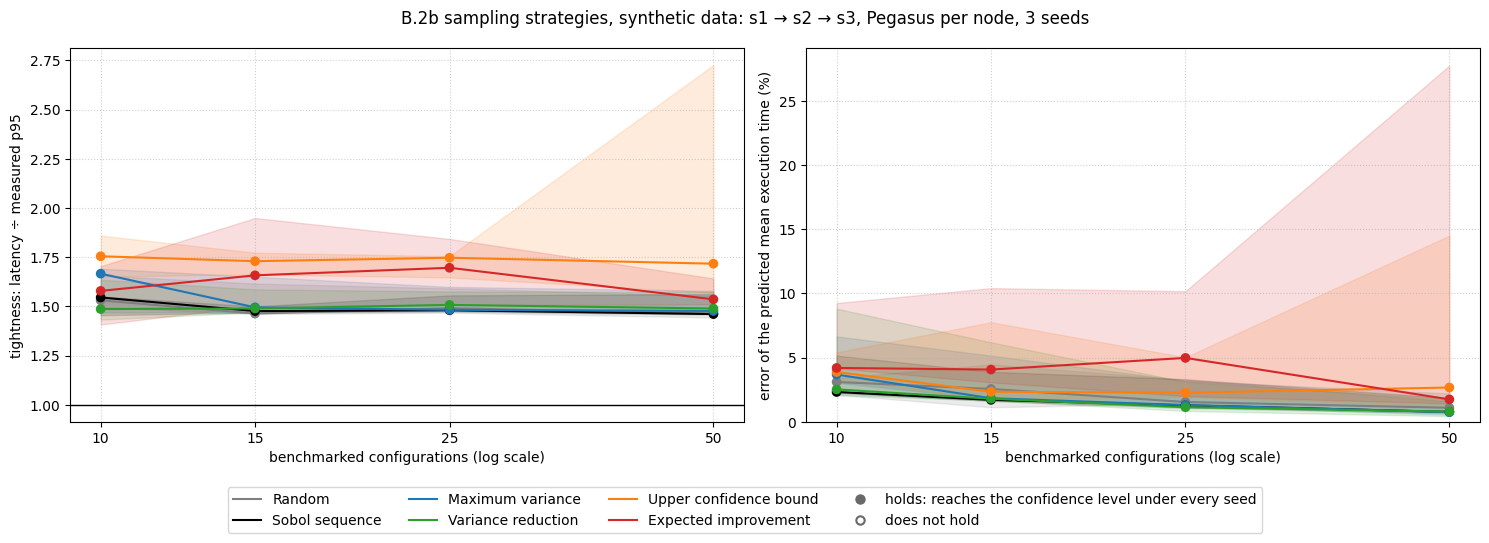

In [10]:
explore_statistics = sweep_statistics(explore_bounds, explore_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
exploration_figure(explore_sizes, explore_statistics, explore_error,
                   f"B.2b sampling strategies, synthetic data: {' → '.join(synthetic_bases[seeds[0]].path)}, Pegasus per node, {len(seeds)} seeds", p_label)

In [11]:
explore_label = lambda size: f"{size} benchmarks"
error_at = lambda strategy, size: np.median(explore_error[strategy][explore_sizes.index(size)])   # median over the seeds
lowest_coverage = lambda strategy, size: explore_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
display(Markdown(
    f"**What this shows** (synthetic data, Pegasus per node, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(explore_sizes, explore_statistics, list(STRATEGIES), explore_label)
    + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
    + " and ".join(explore_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
    + "; ".join(f"{strategy} {error_at(strategy, explore_sizes[0]):.1%} and {error_at(strategy, explore_sizes[-1]):.1%}" for strategy in STRATEGIES)
    + ".\n- **Lowest coverage over the seeds** with " + explore_label(explore_sizes[0]) + ": "
    + ", ".join(f"{strategy} {lowest_coverage(strategy, explore_sizes[0]):.2f}" for strategy in STRATEGIES)
    + f". The level to reach is {confidence:.2f}."
))

**What this shows** (synthetic data, Pegasus per node, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Random, Sobol sequence, Maximum variance, Variance reduction, Upper confidence bound, Expected improvement. Methods that do not hold, and where: none.
- **Tightness among the methods that hold** (median over the seeds): Random from 1.53× at 10 benchmarks to 1.46× at 50 benchmarks; Sobol sequence from 1.54× at 10 benchmarks to 1.46× at 50 benchmarks; Maximum variance from 1.67× at 10 benchmarks to 1.48× at 50 benchmarks; Variance reduction from 1.49× at 10 benchmarks to 1.49× at 50 benchmarks; Upper confidence bound from 1.75× at 10 benchmarks to 1.72× at 50 benchmarks; Expected improvement from 1.58× at 10 benchmarks to 1.54× at 50 benchmarks.
- **Error of the predicted mean execution time** (median over the seeds) with 10 benchmarks and 50 benchmarks: Random 3.1% and 1.1%; Sobol sequence 2.3% and 0.8%; Maximum variance 3.7% and 0.7%; Variance reduction 2.5% and 0.8%; Upper confidence bound 3.9% and 2.7%; Expected improvement 4.2% and 1.7%.
- **Lowest coverage over the seeds** with 10 benchmarks: Random 1.00, Sobol sequence 1.00, Maximum variance 1.00, Variance reduction 1.00, Upper confidence bound 1.00, Expected improvement 0.99. The level to reach is 0.95.

**Setting (real data; skipped, see above).** The chain, the held-out runs and the ground truth of the real B.1 of the first
campaign (qr → cv → face), for every seed. What differs from the
synthetic part:
- A *benchmark* is one measured run of one service, with the mean and the spread of its processing times (see Training
  data in B.1). A strategy *selects* it from the runs that may train the service: its runs alone and in pipelines of
  another topology, several hundred per service. It sees the configurations of all these runs, and the processing
  times only of the runs it has selected.
- Every service selects its own runs, because the real services have their own knobs; after $n$ selections per
  service, the models are fitted as in B.2.
- The adaptive strategies use the mean model of the real data, a GP on the logarithm of the run means. Their scores
  are therefore relative: the upper confidence bound prefers runs that are slow or uncertain by a factor, and the
  expected improvement is an improvement of the logarithm of the mean processing time.
- A fixed set of runs has no Sobol sequence. Its counterpart is *farthest point*: after the initial random runs, always
  the run whose configuration is farthest from the configurations selected so far (in standardized knobs). Like the
  Sobol sequence, it spreads the runs over the space without looking at a model.

The figure is the one of the synthetic part, with the number of selected runs per service on the horizontal axis. A
strategy has no point where, for half of the seeds or more, the bound is infinite at half of the held-out runs or
more.

In [12]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    # B.2b, real data: every service selects its training runs one by one among its measured runs (real_exploration_results in
    # pegasus/exploration.py). This cell imports what it needs itself, so nothing above has to be run again.
    from pegasus.exploration import POOL_STRATEGIES, real_exploration_results

    explore_experiment = "04e-chain-qr-cv-face"   # the real chain of B.1
    real_bases = bases if data_source == "real" else {
        s: load_chain_data("real", experiment=explore_experiment, utilization=0.5, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s]) for s in seeds}
    pool_bounds, pool_truth = {}, {}                                                                    # (size, seed) -> strategy -> ("proposed", latency per held-out run) / truth
    pool_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in POOL_STRATEGIES}   # relative error of the predicted mean
    with warnings.catch_warnings():
        # with few runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            for strategy in POOL_STRATEGIES:
                results = real_exploration_results(explore_experiment, real_bases[s], strategy, explore_sizes, n_initial, seed=[seed, s, 300], alpha=alpha,
                                                   confidence=confidence, model_seed=seed + s)
                for i, size in enumerate(explore_sizes):
                    pool_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                    pool_truth[(size, s)] = (real_bases[s].measured, real_bases[s].measured_low)
                    pool_error[strategy][i, j] = results[size][1]
    print(f"{len(POOL_STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

B.2b real skipped: not supported by the real data


In [13]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_statistics = sweep_statistics(pool_bounds, pool_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
    exploration_figure(explore_sizes, pool_statistics, pool_error,
                       f"B.2b sampling strategies, real data: {' → '.join(real_bases[seeds[0]].path)}, Pegasus per node, {len(seeds)} seeds", p_label,
                       xlabel="selected runs per service (log scale)")

B.2b real skipped: not supported by the real data


In [14]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_label = lambda size: f"{size} selected runs"
    pool_error_at = lambda strategy, size: np.median(pool_error[strategy][explore_sizes.index(size)])   # median over the seeds
    pool_lowest = lambda strategy, size: pool_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
    display(Markdown(
        f"**What this shows** (real data, Pegasus per node, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(explore_sizes, pool_statistics, list(POOL_STRATEGIES), pool_label)
        + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {pool_error_at(strategy, explore_sizes[0]):.1%} and {pool_error_at(strategy, explore_sizes[-1]):.1%}" for strategy in POOL_STRATEGIES)
        + ".\n- **Finite bounds.** Share of the held-out runs with a finite bound (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {finite_share(pool_bounds, strategy, explore_sizes[0], seeds):.0%} and {finite_share(pool_bounds, strategy, explore_sizes[-1], seeds):.0%}"
                    for strategy in POOL_STRATEGIES)
        + ".\n- **Lowest coverage over the seeds** with " + pool_label(explore_sizes[0]) + ": "
        + ", ".join(f"{strategy} {pool_lowest(strategy, explore_sizes[0]):.2f}" for strategy in POOL_STRATEGIES)
        + f". The level to reach is {confidence:.2f}."
    ))

B.2b real skipped: not supported by the real data


### B.3 Varying Chain Depth

- **Synthetic:** chains of 1 to 50 generated service types.
- **Real:** skipped. Every chain of the second campaign has three services, so there is no second depth.
- **Baselines:** as in B.1 without DNN Sum. The conformal bound splits its budget over the services, like the union bound.

**Setting (synthetic data).** Chains of depth $K$ (`depths`) of $K$ different service types, $s_1 \to s_2 \to \dots \to s_K$
(`synthetic_chain`): the chain of depth 3 is the chain of B.1, and every deeper chain adds further service types.
Every position has its own queue, and all positions run at the same configuration. The training configurations and
the held-out configurations are those of B.1 at every depth, every service has its own training data, and the ground
truth is simulated anew for every depth. All of this is repeated for every seed in `seeds`. Metrics and methods are those of B.1.

Two things change with the depth for every method that splits the violation budget (Pegasus per node, Quantile Union,
Conformal, Oracle): each service is bounded at the level $1 - \varepsilon / K$, which moves further into the tail as $K$
grows. The runs that Quantile Union, Conformal and the Oracle read that quantile from have a fixed number of items, so
for the deepest chains only a handful of items lie beyond it and their values rest on very few observations.
Pegasus SNC does not split the budget: it bounds the whole chain at $\varepsilon$, with one parameter θ shared by all
services.

**Complexity (against the depth).** Training time and evaluation time are defined in B.1 (Metrics).
- *Training.* Every method trains one model per service, and a chain of depth $K$ has $K$ services, so every training
  time is expected to grow linearly with $K$.
- *Evaluation.* A node bound of Pegasus per node is one formula and a short search on it, so its cost does not depend
  on the budget $\varepsilon / K$ of a service, and every position of a chain gets its own node bound. Pegasus SNC adds
  one latency moment per position, on a grid of values of θ, and minimizes once over that grid. Both versions also
  predict with one GP per service. The evaluation time of both is therefore expected to grow linearly with $K$.
- The conclusion below the figure gives the measured exponent of $K$ between the two deepest chains: an exponent of 1
  is linear growth, and an exponent below 1 means that the part of the time that does not depend on $K$ is still
  visible at these depths.

**Figure.** Three panels with the depth $K$ on the horizontal axis (logarithmic). *Left:* tightness, for every seed the
median over its held-out configurations. The horizontal line at 1× is the measured quantile: a value under that line
is below the measured quantile. *Middle:* training time (s, logarithmic), one line per set of trained models; the
legend inside the panel names the methods that use these models. *Right:* evaluation time (s, logarithmic), one line
per method. Every line is the median over the seeds, and the band around it reaches from the smallest to the largest
seed. In the left panel a filled marker means that the method holds at that depth (it reaches the confidence level
under every seed, as defined in B.1), and a hollow marker that it does not. Look at the markers first: only lines with
filled markers are bounds whose tightness can be compared.

In [15]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    # B.3: chains of different depth
    depth_truth, depth_methods, depth_seconds = {}, {}, {}   # (depth, seed) -> ...
    with warnings.catch_warnings():
        # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            for depth in depths:
                data = load_chain_data(data_source, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], **depth_options(depth, s))
                if data_source == "synthetic":   # every position a different service type, at the held-out configurations of B.1
                    assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                assert_unseen(data)
                models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                depth_methods[(depth, s)], depth_seconds[(depth, s)] = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence,
                                                                                       n_calibration, model_seed=seed + s, leave_out=only_base_case,
                                                                                       x_train_load=data.x_train_load)
                depth_truth[(depth, s)] = (data.measured, data.measured_low)   # the traces of a deep chain are large, so only the measured quantile is kept
                if s == seeds[0] and depth == depths[-1]:   # one deepest chain, for the figure of the minimum spacing
                    deepest_path, deepest_models, deepest_x_test = data.path, models, data.x_test
            print(f"seed {s}: depths up to {depths[-1]} evaluated")

B.3 skipped: not supported by the real data


In [16]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    depth_statistics = sweep_statistics(depth_methods, depth_truth, depths, seeds, confidence)   # name -> coverage, tightness, holds, computed
    depth_times = sweep_seconds(depth_seconds, depths, seeds)                                    # name -> training, evaluation
    tightness_and_time_figure(depths, depth_statistics, depth_times, "chain depth K (log scale)",
                              f"B.3 chain depth, {data_source} data, {len(seeds)} seeds", p_label)

B.3 skipped: not supported by the real data


In [17]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    depth_label = lambda depth: f"depth {depth}"
    # exponent of K between the two deepest chains, from the medians over the seeds: 1 means that the time grows linearly with the depth
    growth = lambda seconds: np.log(np.median(seconds[-1]) / np.median(seconds[-2])) / np.log(depths[-1] / depths[-2])
    display(Markdown(
        f"**What this shows** ({data_source} data, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(depths, depth_statistics, sweep_competitors, depth_label) + "\n"
        + ground_truth_conclusion(depths, depth_truth, depth_statistics, seeds, depth_label, p_label) + "\n"
        + time_conclusion(depths, depth_times, sweep_competitors, depth_label)
        + f"\n- **Growth with the depth.** Between depth {depths[-2]} and depth {depths[-1]} the time grows with K to the power "
        f"{growth(depth_times[PROPOSED]['training']):.1f} (training of the execution-time GPs), "
        + " and ".join(f"{growth(depth_times[name]['evaluation']):.1f} (evaluation of {name})" for name in pegasus_versions) + "."
    ))

B.3 skipped: not supported by the real data


**Figure (minimum spacing).** This figure concerns Pegasus per node only; Pegasus SNC does not use the spacing between
the departures of a service. The figure below shows the deepest chain of the first seed position by position: the
processing time of every service (the mean execution time that its GP predicts, in ms) and the *minimum spacing* of its
arrivals. The minimum spacing is the smallest gap that two consecutive items can have when they arrive at the service.
It equals the processing time of the service before, because that service handles one item at a time and so cannot
release two items closer together than it needs for one. The actual gaps are usually larger. Lines are the median over
the held-out configurations, bands the first to third quartile. Where the minimum spacing lies below the processing
time, the service sits behind a faster one: items can arrive faster than it processes them for a while, and it can
queue; these positions are circled. The conclusion below the figure gives two shares over all later positions and
held-out configurations: how often the service before is faster, and how often Pegasus per node cannot use the minimum
spacing, which is more often, because Pegasus per node requires the optimistic mean of the service before to exceed the
pessimistic mean of the service itself. In those cases Pegasus per node falls back on the external arrivals.

In [18]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    # The deepest chain: processing time of every service and minimum spacing of its arrivals, as the models predict them
    processing = np.array([deepest_models["gp"][s].predict(configurations_of(deepest_x_test, s)) for s in deepest_path]) * 1e3   # (positions, configurations), ms
    spacing = processing[:-1]                                    # minimum spacing of the arrivals at the positions 2, 3, ...: processing time of the service before
    behind_faster = np.mean(spacing < processing[1:], axis=1)    # share of the held-out configurations, per position
    pessimistic_mean = np.array([mean for mean, _ in deepest_models["beliefs"]])
    no_spacing_used = np.mean(np.array(deepest_models["lower_means"])[:-1] <= pessimistic_mean[1:], axis=1)   # Pegasus needs a clear margin between the two
    positions = np.arange(1, len(deepest_path) + 1)
    quartiles = lambda values: np.quantile(values, [0.25, 0.5, 0.75], axis=1)

    fig, ax_spacing = plt.subplots(figsize=(14, 5))
    for values, where, color, style, label in ((processing, positions, "tab:blue", "o-", "processing time of the service"),
                                               (spacing, positions[1:], "tab:orange", "s--", "minimum spacing of its arrivals: processing time of the service before")):
        low, middle, high = quartiles(values)
        ax_spacing.plot(where, middle, style, color=color, markersize=3, linewidth=1, label=label)
        ax_spacing.fill_between(where, low, high, color=color, alpha=0.15)
    faster_before = quartiles(spacing)[1] < quartiles(processing[1:])[1]
    ax_spacing.scatter(positions[1:][faster_before], quartiles(processing[1:])[1][faster_before], s=70, facecolors="none", edgecolors="tab:red", linewidths=1.5,
                       label="service behind a faster one (median over the configurations)")
    ax_spacing.set_ylabel("predicted mean time (ms)")
    ax_spacing.set_xlabel(f"position in the chain of depth {len(deepest_path)}")
    ax_spacing.legend(loc="upper right", fontsize=9)
    ax_spacing.grid(True, linestyle=":", alpha=0.6)
    fig.suptitle(f"B.3 minimum arrival spacing along the chain of depth {len(deepest_path)}, {data_source} data, seed {seeds[0]}, {processing.shape[1]} held-out configurations")
    plt.tight_layout()
    plt.show()

B.3 skipped: not supported by the real data


In [19]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    display(Markdown(
        f"**What this shows** ({data_source} data, the chain of depth {len(deepest_path)} under seed {seeds[0]}; shares over all later positions and "
        f"held-out configurations).\n"
        f"- The service before is faster in {np.mean(behind_faster):.0%} of the cases. There the minimum spacing lies below the processing time of the "
        f"service, so the service can queue even though the service before releases one item at a time.\n"
        f"- Pegasus per node cannot use the minimum spacing in {np.mean(no_spacing_used):.0%} of the cases and bounds the service with the external "
        f"arrivals there, like the first service of the chain. In the remaining {1 - np.mean(no_spacing_used):.0%} its node bound also uses the minimum spacing."
    ))

B.3 skipped: not supported by the real data


### B.4 Varying Load and Arrival Pattern

- **Synthetic:** the load (any arrival rate, B.4a) and the variability of the arrivals (renewal arrivals with
  gamma-distributed gaps of any squared coefficient of variation $C^2$, B.4b). Batching and diurnal arrivals are not
  implemented.
- **Real:** skipped (B.4a and B.4b). The campaign measured every run under Poisson arrivals at one rate that it set
  for that run, so neither the load nor the arrival pattern can be changed.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal need every service monitored at every load and
  arrival pattern; the execution-time baseline and the proposed method do not.

B.4 has two parts. B.4a changes how many items arrive per second (the load), and B.4b changes how evenly the items
arrive at the same rate (the arrival pattern).

**Setting of both parts.** For every seed, the chain, the training configurations, the per-service execution-time
models and the held-out configurations of B.1. Execution times do not depend on the arrivals, so these models are
used unchanged. Only the arrival process at the first service changes, and the ground truth is simulated anew for
every setting.

What each method knows about the arrivals: both versions of Pegasus are given the arrival process (they use the moment
generating function of the gap between two arrivals), and Kingman is given the arrival rate and $C^2$. Quantile Union
and Conformal are trained anew for every setting, on each service monitored alone under the arrival process of that
setting. GP Sum ignores the arrivals, so its latency is the same in every setting.

#### B.4a Load

**Setting (synthetic data).** Poisson arrivals as in B.1, with the arrival rate $\lambda$ (items/s), one value of `loads` per
setting. The rate of B.1 is one of them, and that setting is the base case again. The *utilization* of a service at a
configuration is $\rho = \lambda \cdot$ (mean execution time of the service at that configuration, in seconds) ÷ (its
number of workers): the share of the time in which every worker of the service is busy. At $\rho \geq 1$ items arrive faster than the service processes them,
its queue grows without limit, and no latency quantile exists. The rates are therefore chosen so that no service is
overloaded at any held-out configuration under any seed; the code checks this with the true mean execution times of
the generated services. The *busiest service* of a chain at a configuration is the service with the largest
utilization.

**What to expect.** The waiting time at a service grows without limit as its utilization approaches 1 (in Kingman's
formula with the factor $\rho / (1 - \rho)$). With a higher rate, the queues therefore make up a larger part of the
latency; GP Sum ignores that part. Both versions of Pegasus bound a service with the pessimistic mean of its execution
time, which lies above the true mean. Where the utilization computed with the pessimistic mean reaches 1, they give no
finite bound, although the service is stable.

**Figure.** The horizontal axis is the arrival rate (items/s); under every tick stands the utilization of the busiest
service, the median over the held-out configurations of all seeds. The vertical axis is the tightness, for every seed
the median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every
line is the median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled
marker means that the method holds at that rate (it reaches the confidence level under every seed, as defined in
B.1), a hollow marker that it does not. A seed under which a method gives no finite latency at half of the held-out
configurations or more counts as infinitely loose, and the method has no point where that is the case for half of the
seeds or more. Look at the markers first, then at whether the filled lines move away from 1× toward the higher rates.

In [20]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    # B.4a: the chains of B.1 under Poisson arrivals of different load (`loads`: arrival rate with synthetic data, utilization of the busiest service with real data)
    base_load = workload["rate"] if data_source == "synthetic" else base_utilization
    assert base_load in loads, "the load of B.1 is not one of the settings"
    # Training runs per service. Real data: more than in B.1, because close to saturation a bound only exists if the mean execution
    # time is known precisely (see the text above). Synthetic data: the models of B.1.
    load_n_train = 100 if data_source == "real" else n_train
    load_methods, load_truth, load_models, load_y_train = {}, {}, {}, {}   # (load, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge); seed -> models / their training data
    with warnings.catch_warnings():
        # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for load in loads:
            for s in seeds:
                data = chain_data(s, n_train=load_n_train, **{load_option: load})
                assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                if s not in load_models:   # the execution times do not depend on the arrivals, so every load uses the same per-service models
                    load_models[s], load_y_train[s] = (base_models[s] if load_n_train == n_train else fit_services(
                        data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)), data.y_train
                assert all(np.array_equal(data.y_train[name], load_y_train[s][name]) for name in data.path), "the training data differs between the loads"
                load_methods[(load, s)], _ = compare_methods(data, load_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                             model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
                load_truth[(load, s)] = (data.measured, data.measured_low)
    # true utilization of the busiest service per held-out configuration, the seeds one after the other; with real data it is the load itself
    load_utilization = {load: np.concatenate([busiest_utilization(base.path, bases[s].x_test, load, service_seed=s) for s in seeds])
                        if data_source == "synthetic" else np.full(len(base.measured), load) for load in loads}
    assert max(utilization.max() for utilization in load_utilization.values()) < 1, "a service is overloaded at a held-out configuration"
    print(f"{len(load_methods)} combinations of load and seed evaluated.")

B.4a skipped: not supported by the real data


In [21]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    load_statistics = sweep_statistics(load_methods, load_truth, loads, seeds, confidence)   # name -> coverage, tightness, holds, computed
    load_axis = ("arrival rate (items/s; below: utilization of the busiest service, median over the configurations)" if data_source == "synthetic"
                 else "utilization of the busiest service of every run")
    tightness_sweep_figure(loads, load_statistics, load_axis,
                           f"B.4a load, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                           f"{workload['process']} arrivals, {len(seeds)} seeds", p_label,
                           tick_labels=[f"{load:g}\n{np.median(load_utilization[load]):.2f}" if data_source == "synthetic" else f"{load:g}" for load in loads],
                           log_x=False)

B.4a skipped: not supported by the real data


In [22]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    display(Markdown(
        f"**What this shows** ({data_source} data, {workload['process']} arrivals, ε = {alpha:g}, {len(seeds)} seeds).\n"
        f"- **Load.** Utilization of the busiest service over the held-out configurations of all seeds: "
        + "; ".join(f"median {np.median(load_utilization[load]):.2f} and maximum {load_utilization[load].max():.2f} at {load_label(load)}"
                    for load in (loads[0], loads[-1])) + ".\n"
        + sweep_conclusion(loads, load_statistics, sweep_competitors, load_label)
        + f"\n- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): "
        + "; ".join(f"{name} " + ", ".join(f"{finite_share(load_methods, name, load, seeds):.0%} at {load_label(load)}" for load in loads)
                    for name in pegasus_versions)
        + ". Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded at that "
        f"load, although its true utilization is below 1.\n"
        + ground_truth_conclusion(loads, load_truth, load_statistics, seeds, load_label, p_label, ", for the same services and configurations")
    ))

B.4a skipped: not supported by the real data


#### B.4b Arrival Pattern

**Setting.** A *gap* is the time between two consecutive arrivals at the first service, in seconds. The gaps are
independent and gamma-distributed with the mean of B.1 (1 ÷ arrival rate) and the squared coefficient of variation
$C^2$ = variance of a gap ÷ (mean of a gap)², one value of `arrival_cv2s` per setting. $C^2 = 1$ gives the exponential
gaps of a Poisson process, as in B.1. Below 1 the arrivals are spaced more evenly; above 1 they come in bursts with
long pauses between them. The arrival rate, and with it the utilization of every service, is the same in every
setting, so only the variability of the arrivals changes.

**Figure.** The horizontal axis is $C^2$ (logarithmic), the vertical axis the tightness, for every seed the median over
its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line is the median
over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that the
method holds at that $C^2$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker that
it does not. Look at the markers first, then at how the filled lines move from left to right.

In [23]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    # B.4b: the chains of B.1 under arrivals of different variability at the arrival rates of B.1
    arrival_cv2s = [0.25, 0.5, 1, 2, 4]   # squared coefficient of variation of the gaps between arrivals; 1 is the Poisson process of B.1
    arrival_methods, arrival_truth = {}, {}   # (cv2, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
    for cv2 in arrival_cv2s:
        for s in seeds:
            data = chain_data(s, arrival_process="gamma", arrival_cv2=cv2)
            assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
            assert np.array_equal(data.workload["rate"], bases[s].workload["rate"]), "the arrival rates differ from those of B.1"
            # the execution times do not depend on the arrivals, so the per-service models of B.1 are the models of every setting
            assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
            arrival_methods[(cv2, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                           model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
            arrival_truth[(cv2, s)] = (data.measured, data.measured_low)
    gamma_arrivals = arrival_text(data.workload)
    print(f"{len(arrival_methods)} combinations of arrival variability and seed evaluated.")

B.4b skipped: not supported by the real data


In [24]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    arrival_statistics = sweep_statistics(arrival_methods, arrival_truth, arrival_cv2s, seeds, confidence)   # name -> coverage, tightness, holds, computed
    tightness_sweep_figure(arrival_cv2s, arrival_statistics, "squared coefficient of variation C² of the gaps between arrivals (log scale)",
                           f"B.4b arrival variability, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                           f"{gamma_arrivals}, {len(seeds)} seeds", p_label)

B.4b skipped: not supported by the real data


In [25]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    cv2_label = lambda cv2: f"C² = {cv2:g}"
    display(Markdown(
        f"**What this shows** ({data_source} data, {gamma_arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(arrival_cv2s, arrival_statistics, sweep_competitors, cv2_label) + "\n"
        + ground_truth_conclusion(arrival_cv2s, arrival_truth, arrival_statistics, seeds, cv2_label, p_label, ", at the same arrival rates")
    ))

B.4b skipped: not supported by the real data


### B.5 Varying Tail Behaviors

- **Synthetic:** the execution time of an item gets a lognormal factor whose shape sets how heavy the right tail is
  (`execution_times` in `pegasus/simulation.py`).
- **Real:** a real service has no knob for its tail. The held-out configurations of B.1 are grouped by the tail that
  the testbed measured.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal assume no distribution; the execution-time
  baseline shares the Gaussian assumption.

**Setting (real data).** Nothing is computed anew: the results of B.1 are split into three groups of held-out
configurations of equal size. The *tail ratio* of a run is the 99th percentile ÷ the median of the measured processing
time, for the service of the run at which that ratio is largest; a ratio of 1 would be a processing time without any
scatter. The runs are sorted by their tail ratio and cut into thirds. The horizontal axis of the figure shows the
three groups with the median tail ratio of each. Unlike with synthetic data, the groups also differ in their
configurations, so the tail is not the only thing that changes between them, and a group has a third of the held-out
configurations, so one miss weighs three times as much in its coverage.

**Setting (synthetic data).** For every seed, the chain, the training configurations, the held-out configurations and the Poisson
arrivals of B.1. Only the distribution of the execution time changes. The execution time of an item is its mean
execution time (the same function of the configuration as in B.1) multiplied by a factor $e^{\sigma z - \sigma^2/2}$,
where $z$ is the standard normal draw of the item and $\sigma$ the *tail shape*, one value of `execution_tails` per
setting; the Gaussian noise of B.1 is added as before. The factor is lognormal with mean 1, so the mean execution time
and the utilization of every service are the same in every setting. $\sigma = 0$ is the Gaussian execution time of
B.1. With a larger $\sigma$ most items are faster than the mean and a few are several times slower: the squared
coefficient of variation of the factor, variance ÷ mean², is $e^{\sigma^2} - 1$ and is printed under every tick of the
figure. The tail and the variance of the execution time therefore grow together.

Every model is trained anew for every $\sigma$, on data with that tail: one execution time per service and training
configuration for both versions of Pegasus, GP Sum and Kingman, and each service monitored alone for Quantile Union and
Conformal. No method is told the distribution. Both versions of Pegasus, GP Sum and Kingman treat an execution time as
Gaussian with the mean and the variance that the model of the service learned; Quantile Union and Conformal learn
latency quantiles and assume no distribution.

**Figure.** The horizontal axis is the tail shape $\sigma$, the vertical axis the tightness, for every seed the median
over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that
the method holds at that $\sigma$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker
that it does not. A seed under which a method gives no finite latency at half of the held-out configurations or more
counts as infinitely loose, and the method has no point where that is the case for half of the seeds or more; such a
bound is not violated, but it says nothing.

In [26]:
# B.5: execution times of different tail
tail_methods, tail_truth = {}, {}   # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
if data_source == "synthetic":
    # the chains of B.1 with execution times of different tail shape
    execution_tails = [0, 0.25, 0.5, 0.75, 1.0]   # shape sigma of the lognormal factor of the execution time; 0 is the Gaussian execution time of B.1
    with warnings.catch_warnings():
        # with heavy-tailed training data the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every such model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for tail in execution_tails:
            for s in seeds:
                data = chain_data(s, execution_tail=tail)
                assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                assert_unseen(data)
                models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                tail_methods[(tail, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                             model_seed=seed + s, leave_out=only_base_case)
                tail_truth[(tail, s)] = (data.measured, data.measured_low)
    factor_cv2 = lambda tail: np.expm1(tail ** 2)   # squared coefficient of variation of the lognormal factor with shape `tail`
    tail_label = lambda tail: f"σ = {tail:g}"
    tail_axis = "tail shape σ of the execution time (below: squared coefficient of variation of its factor)"
    tail_ticks = [f"{tail:g}\n{factor_cv2(tail):.2f}" for tail in execution_tails]
else:
    # the held-out configurations of B.1 in three groups of equal size, by the measured tail of their processing times
    tail_ratio = chain_tail_ratios(base_experiment, base_split[1])               # per held-out run: p99 / median of the processing time, largest over its services
    tail_group = np.digitize(tail_ratio, np.quantile(tail_ratio, [1 / 3, 2 / 3]))   # 0, 1, 2: lightest to heaviest third
    execution_tails = [float(np.median(tail_ratio[tail_group == g])) for g in range(3)]   # a group is named by its median tail ratio
    for g, tail in enumerate(execution_tails):
        for s, (seed_methods, _) in zip(seeds, per_seed):
            tail_methods[(tail, s)] = {name: (group, latency[tail_group == g]) for name, (group, latency) in seed_methods.items() if name not in only_base_case}
            tail_truth[(tail, s)] = (bases[s].measured[tail_group == g], bases[s].measured_low[tail_group == g])
    tail_label = lambda tail: f"tail ratio {tail:.2f}"
    tail_axis = "third of the held-out configurations (below: its median tail ratio, p99 ÷ median of the processing time)"
    tail_ticks = [f"{name}\n{tail:.2f}" for name, tail in zip(("lightest", "middle", "heaviest"), execution_tails)]
print(f"{len(tail_methods)} combinations of tail and seed evaluated.")

9 combinations of tail and seed evaluated.


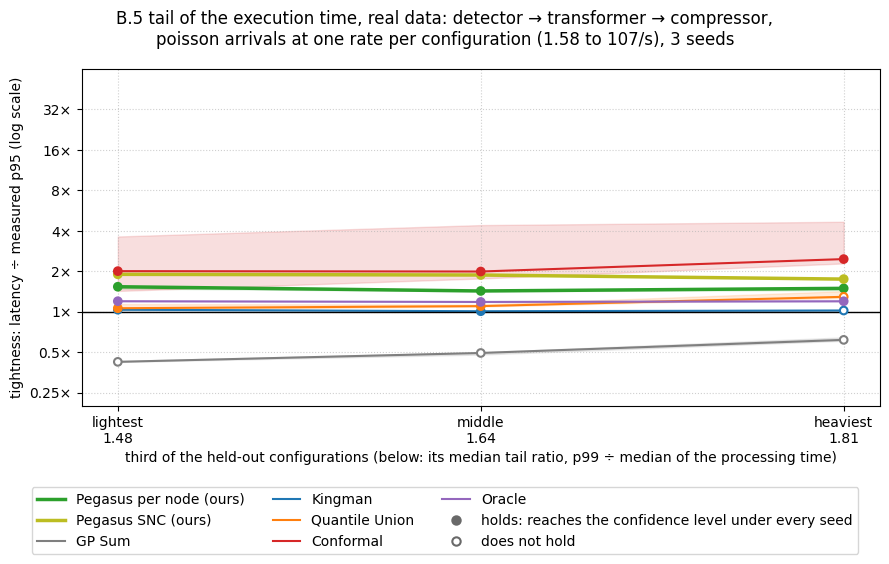

In [27]:
tail_statistics = sweep_statistics(tail_methods, tail_truth, execution_tails, seeds, confidence)   # name -> coverage, tightness, holds, computed
# with real data the three groups are placed at equal distances, because their tail ratios are not spread evenly
tail_positions = execution_tails if data_source == "synthetic" else list(range(len(execution_tails)))
tightness_sweep_figure(tail_positions, tail_statistics, tail_axis,
                       f"B.5 tail of the execution time, {data_source} data: {' → '.join(base.path)},\n{arrivals}, {len(seeds)} seeds", p_label,
                       tick_labels=tail_ticks, log_x=False)

In [28]:
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(execution_tails, tail_statistics, sweep_competitors, tail_label)
    + f"\n- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): "
    + "; ".join(f"{name} " + ", ".join(f"{finite_share(tail_methods, name, tail, seeds):.0%} at {tail_label(tail)}" for tail in execution_tails)
                for name in pegasus_versions)
    + ". Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound "
    f"is not violated, but it says nothing.\n"
    + ground_truth_conclusion(execution_tails, tail_truth, tail_statistics, seeds, tail_label, p_label,
                              ", at the same mean execution times" if data_source == "synthetic" else "")
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 107/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where: GP Sum at every setting; Kingman at tail ratio 1.48, tail ratio 1.81; Quantile Union at tail ratio 1.81.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 1.53× at tail ratio 1.48 to 1.49× at tail ratio 1.81; Pegasus SNC (ours) from 1.90× at tail ratio 1.48 to 1.75× at tail ratio 1.81; Conformal from 2.00× at tail ratio 1.48 to 2.46× at tail ratio 1.81.
- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): Pegasus per node (ours) 100% at tail ratio 1.48, 100% at tail ratio 1.64, 100% at tail ratio 1.81; Pegasus SNC (ours) 100% at tail ratio 1.48, 100% at tail ratio 1.64, 100% at tail ratio 1.81. Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound is not violated, but it says nothing.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.53 s at tail ratio 1.48 to 0.06 s at tail ratio 1.81. The Oracle, the union bound over measured services, is at 1.20× and 1.19×.

### B.6 Varying Percentiles

- **Synthetic:** every percentile that the simulated runs are long enough to measure.
- **Real:** the same, on the measured held-out runs of B.1; a run measured a few hundred to a few thousand requests,
  so the highest percentiles rest on few requests per run.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal train one model per percentile; the other
  methods use the same execution-time models at every percentile.

**Setting.** For every seed, the chain, the training configurations, the per-service models, the held-out
configurations, the Poisson arrivals and the simulated or measured runs of B.1. Only the percentile that a method has to bound
changes: the *level* is the share of items whose end-to-end latency must lie under the bound, one value of
`percentile_levels` per setting, written as a percentile (level 0.95 is p95, the percentile of B.1). The violation
probability is $\varepsilon$ = 1 − level, so a higher percentile is a smaller $\varepsilon$. The ground truth is the
measured quantile of the end-to-end latency at that level, with the confidence interval of B.1. The highest level is
limited by the length of the simulated runs: a quantile further in the tail would rest on too few items per run to be
measured, in particular the quantile at $1 - \varepsilon / K$ that Quantile Union, Conformal and the Oracle read from
the runs of each service.

How the level enters each method: Pegasus per node bounds every service at $\varepsilon / K$ and Pegasus SNC the whole
chain at $\varepsilon$, both with the same execution-time models as in B.1. GP Sum takes the level as the quantile of
its Gaussian sum, and Kingman as the quantile of its waiting-time formula. Quantile Union and Conformal are trained
anew for every level, on the $(1 - \varepsilon / K)$ latency quantile of each service monitored alone.

**Figure.** The horizontal axis is the bounded percentile, at equal distances from the lowest to the highest; the
vertical axis is the tightness, the latency of a method ÷ the measured quantile at that percentile, for every seed the
median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line
is the median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker
means that the method holds at that percentile (it reaches the confidence level under every seed, as defined in B.1), a
hollow marker that it does not. Look at the markers first, then at whether a filled line comes closer to 1× or moves
away from it toward the higher percentiles.

In [29]:
# B.6: the chains of B.1 with a different percentile of the end-to-end latency to bound
percentile_levels = [0.5, 0.75, 0.9, 0.95, 0.99]   # level of the bounded latency quantile; the violation probability is 1 - level, and B.1 uses 1 - alpha
percentile_methods, percentile_truth = {}, {}       # (level, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
for level in percentile_levels:
    for s in seeds:
        data = chain_data(s, level=level)
        assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
        # the execution times do not depend on the percentile, so the per-service models of B.1 are the models of every setting
        assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
        percentile_methods[(level, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, 1 - level, confidence, n_calibration,
                                                            model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
        percentile_truth[(level, s)] = (data.measured, data.measured_low)
print(f"{len(percentile_methods)} combinations of percentile and seed evaluated.")

15 combinations of percentile and seed evaluated.


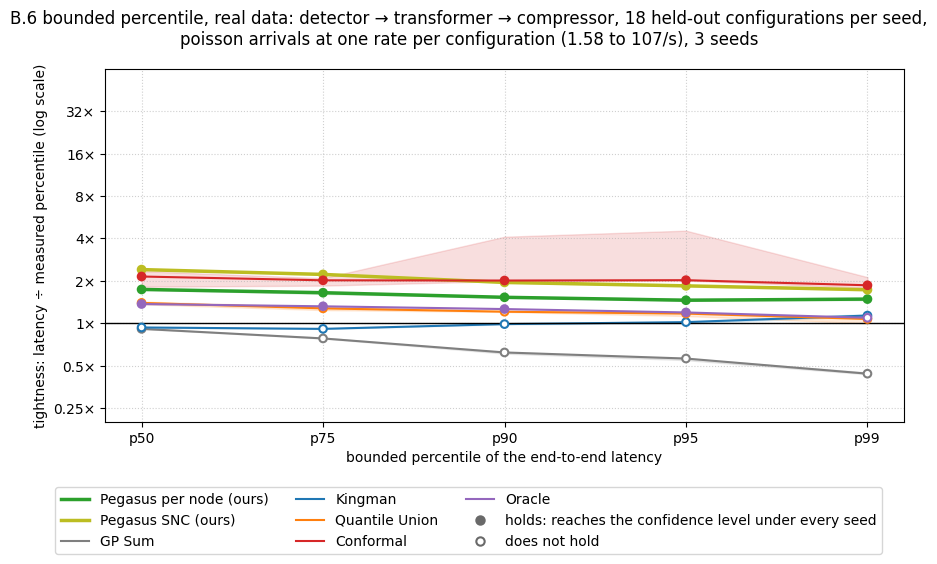

In [30]:
percentile_statistics = sweep_statistics(percentile_methods, percentile_truth, percentile_levels, seeds, confidence)   # name -> coverage, tightness, holds, computed
percentile_label = lambda level: f"p{100 * level:g}"
# the percentiles are placed at equal distances, because neither the level nor the violation probability spreads them evenly
tightness_sweep_figure(list(range(len(percentile_levels))), percentile_statistics, "bounded percentile of the end-to-end latency",
                       f"B.6 bounded percentile, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                       f"{arrivals}, {len(seeds)} seeds", "percentile",
                       tick_labels=[percentile_label(level) for level in percentile_levels], log_x=False)

In [31]:
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, {len(seeds)} seeds).\n"
    + sweep_conclusion(percentile_levels, percentile_statistics, sweep_competitors, percentile_label) + "\n"
    + ground_truth_conclusion(percentile_levels, percentile_truth, percentile_statistics, seeds, percentile_label, "percentile")
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 107/s), 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus per node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where: GP Sum at every setting; Kingman at every setting; Quantile Union at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus per node (ours) from 1.74× at p50 to 1.49× at p99; Pegasus SNC (ours) from 2.41× at p50 to 1.73× at p99; Conformal from 2.15× at p50 to 1.86× at p99.
- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out configurations, goes from 0.12 s at p50 to 0.27 s at p99. The Oracle, the union bound over measured services, is at 1.37× and 1.09×.

## C. Iterative Optimization of Service Bounds

**Note (speed of the bounds).** The experiments of this section compute the bound of Pegasus again and again: for every
candidate configuration or composition that an optimizer grades, and after every update with end-to-end samples. Pegasus
per node evaluates one closed formula per service, and Pegasus SNC minimizes once over a fixed grid of θ. B.2 and B.3 (synthetic data only)
report the evaluation time of both versions, against the amount of training data and against the depth of the chain.

### C.1 Fine-Tuning Bounds with E2E Samples

- **Synthetic:** the chain of B.1, with a part of its held-out configurations as end-to-end samples.
- **Real:** skipped. The held-out runs of B.1 are too few to provide both the end-to-end samples and a test set
  (calibrating at the level `confidence` alone needs at least 19 samples, see Fine-tuning below).
- **Baselines:** the only experiment with models trained on runs of the chain, because using end-to-end samples is
  its subject: Quantile Sum and the Fluxion-style composition, with a growing number of samples. Deep GP Advanced is
  left out: it needs minutes of training per number of samples and seed (`1_method_synthetic.ipynb`, Section 7d, shows
  it on the synthetic system). Reference: the proposed bound without fine-tuning.

**Question.** A bound of B is computed before the chain is ever run. Once the chain runs, every run gives one
*end-to-end sample*: a configuration of the chain together with its measured $(1-\varepsilon)$ latency quantile. How
many samples does it take to tighten the bound, and does it stay valid?

**Setting.** For every seed, the chain, the models and the results of B.1; nothing of B is computed again. The
held-out configurations of B.1 are split at random: `c1_sizes[-1]` of them can serve as end-to-end samples, and the
rest is the test set, which is the same for every number of samples. A setting uses the first $n$ samples, one value
of `c1_sizes` per setting; $n = 0$ is the bound of B.1 on the test set.

**Fine-tuning (`pegasus/finetuning.py`).** The bound is multiplied by one factor that is calibrated on the samples
(split-conformal calibration). The *score* of a sample is its measured quantile ÷ the bound at its configuration:
below 1 where the bound has room, above 1 where the bound is violated. The factor is the
$\lceil (n+1)\,\gamma \rceil$-th smallest score, with $\gamma$ = `confidence`. It lies below 1 if the bound was looser than the
samples require, and the bound becomes tighter; it lies above 1 if the samples violate the bound, and the bound is
raised. If the samples and the configuration that the bound is used at are exchangeable (drawn in the same way), the
fine-tuned bound lies above the measured quantile of that configuration with probability at least $\gamma$. That is a
different guarantee than the one of B: it holds on average over the configurations and the samples, it only holds for
the chain and the workload that the samples were taken from, and it replaces the assumptions of the bound by the
assumption of exchangeability. The rank $\lceil (n+1)\,\gamma \rceil$ must not exceed $n$, so the level $\gamma$ needs a
minimum number of samples; with fewer, the bound stays as it is and keeps the guarantee of B. An infinite bound stays
infinite.

**Baselines trained on the samples.**
- *Quantile Sum:* one GP per service predicts the $(1-\varepsilon)$ latency quantile that the service had inside the
  chain, from the configuration of the service; the predictions are added. It is not a baseline of B, because it needs
  runs of the chain.
- *Fluxion-style:* one GP per position of the chain and quantile level, which receives the configuration of the chain
  and the predicted quantiles of the position before it (`pegasus/baselines_chain.py`, part 4).

Neither is a guarantee: both are point predictions of the quantile. With $n = 0$ they cannot be trained.

**Figure.** The horizontal axis is the number of end-to-end samples $n$ (at equal distances), the vertical axis the
tightness on the test set, for every seed the median over its test configurations (logarithmic). The horizontal line
at 1× is the measured quantile. Every line is the median over the seeds, and the band around it reaches from the
smallest to the largest seed. A filled marker means that the method holds at that $n$ (it reaches the confidence level
on the test set under every seed, as defined in B.1), a hollow marker that it does not. The test set is smaller than
the held-out set of B.1, so one missed configuration weighs more in the coverage. Look at where the fine-tuned lines
leave the lines of the bounds without fine-tuning, and whether their markers stay filled.

In [32]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    # C.1: the results of B.1 with a part of the held-out configurations as end-to-end samples. This cell imports what it needs
    # itself, so that nothing above has to be run again.
    from pegasus.finetuning import COLORS as C1_COLORS, FINETUNED, finetuning_methods, split_samples

    METHOD_COLORS.update(C1_COLORS)   # colors of the fine-tuned bounds and of the two baselines of C.1
    c1_sizes = [0, 5, 10, 20, 25]     # number of end-to-end samples; 0 is the bound of B.1 on the test set
    c1_methods, c1_truth, c1_factors = {}, {}, {}   # (size, seed) -> name -> (group, latency per test configuration) / (measured quantile, its lower edge)
    with warnings.catch_warnings():
        # the GPs of the two baselines are fitted on few samples, and scikit-learn warns where their hyperparameters end at their bounds
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s, (seed_methods, _) in zip(seeds, per_seed):
            samples, test = split_samples(len(bases[s].measured), c1_sizes[-1], np.random.default_rng([seed, s, 100]))
            for size in c1_sizes:
                c1_methods[(size, s)] = finetuning_methods(bases[s], seed_methods, samples[:size], test, alpha, miscoverage=1 - confidence)
                c1_truth[(size, s)] = (bases[s].measured[test], bases[s].measured_low[test])
    n_c1_test = len(test)
    print(f"{len(c1_methods)} combinations of sample size and seed evaluated, {n_c1_test} test configurations per seed.")

C.1 skipped: not supported by the real data


In [33]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    c1_statistics = sweep_statistics(c1_methods, c1_truth, c1_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
    tightness_sweep_figure(list(range(len(c1_sizes))), c1_statistics, "number of end-to-end samples n",
                           f"C.1 fine-tuning with end-to-end samples, {data_source} data: {' → '.join(base.path)}, {n_c1_test} test configurations per seed,\n"
                           f"{arrivals}, {len(seeds)} seeds", p_label, tick_labels=[str(size) for size in c1_sizes], log_x=False)

C.1 skipped: not supported by the real data


In [34]:
if "C.1" in skipped:
    print("C.1 skipped: not supported by the {} data".format(data_source))
else:
    c1_label = lambda size: f"n = {size}"
    c1_names = pegasus_versions + list(C1_COLORS)
    median_tightness = lambda name, size: np.nanmedian(c1_statistics[name]["tightness"][c1_sizes.index(size)])   # median over the seeds
    enough = [size for size in c1_sizes if c1_statistics[FINETUNED[PROPOSED]]["computed"][c1_sizes.index(size)]
              and not np.allclose(c1_statistics[FINETUNED[PROPOSED]]["tightness"][c1_sizes.index(size)], c1_statistics[PROPOSED]["tightness"][c1_sizes.index(size)],
                                  equal_nan=True)]
    display(Markdown(
        f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds, {n_c1_test} test configurations per seed).\n"
        + sweep_conclusion(c1_sizes, c1_statistics, c1_names, c1_label)
        + "\n- **When fine-tuning starts to act.** "
        + (f"The fine-tuned bound differs from the bound of B.1 from {c1_label(enough[0])} on; with fewer samples the level "
           f"{confidence:.0%} cannot be calibrated, and the bound stays as it is. " if enough else
           "With none of these numbers of samples can the level be calibrated, so the bound stays as it is. ")
        + f"With {c1_label(c1_sizes[-1])}: "
        + "; ".join(f"{name} {median_tightness(name, c1_sizes[-1]):.2f}× without and {median_tightness(FINETUNED[name], c1_sizes[-1]):.2f}× with fine-tuning"
                    for name in pegasus_versions)
        + " (median over the seeds)."
    ))

C.1 skipped: not supported by the real data


### C.2 Inferring Faster Service Compositions

> **TODO: reformulate C.2.** The objective below maximizes a weighted SLO fulfillment over quality and latency. What
> the experiment should answer instead: what is the *minimum budget of resources* (the cost of a configuration) at
> which the chain reaches the target latency with the target accuracy? Latency and accuracy then become constraints
> that a configuration must meet, and the cost is what the optimizer minimizes. The optimizers, the choice among the
> existing runs and the refitting of the models after every evaluated run can stay; the objective, the metrics and the
> conclusions below have to change.

- **Synthetic:** the chain of B.1; the existing runs are its held-out configurations.
- **Real:** skipped. The optimization needs every run at one common arrival rate (below), but the second campaign
  measured every run at its own rate.
- **Methods:** both versions of Pegasus and the baselines of B.2 to B.6, each under the same two optimizers.
  Reference: random search.

**Question.** A latency model is useful if an optimizer that relies on it finds a good configuration with few runs of
the chain. Which method leads the optimizer to the best configuration, and how fast?

**Objective: SLO fulfillment.** As in the multidimensional scaling paper (Sedlak et al., IEEE TSC), a *service level
objective* (SLO) relates a metric $m$ to a target $t$, and its *fulfillment* $\phi$ is a number between 0 and 1 that
cannot exceed 1: an SLO cannot be overfulfilled.
- *Quality SLOs* (a larger metric is better): $\phi = \min(1, m / t)$. With real data they are the resolution of the
  QR-code detector and of the object detector and the model size of the object detector and of the face detector; with
  synthetic data the quality knob of the configuration. The targets are in the code cell (`quality_slos`).
- *Latency SLO* (a smaller metric is better): $\phi = \min(1, t / m)$, with $m$ the $(1-\varepsilon)$ quantile of the
  end-to-end latency (s) and $t$ = `latency_target`. The target is the median of the measured quantiles of the existing
  runs, so that about half of them meet it. A configuration without a finite latency has $\phi = 0$.

The objective of a configuration is the weighted mean of the fulfillments: the latency SLO has the weight
`latency_weight`, and the quality SLOs share the rest equally. A higher quality makes a service slower, so the two
kinds of SLO pull in opposite directions. The *predicted* objective uses the latency that a method gives for the
configuration; the *true* objective uses the measured quantile.

**One arrival rate for all runs.** An optimizer chooses a configuration for a given workload, so every run has the
same arrival rate here (synthetic data: the one of B.1; real data: `c2_rate`, unlike B, where every real run has its
own rate). A real run whose busiest service is overloaded at that rate has no latency quantile, and its latency SLO is
not fulfilled at all.

**Optimizers (`pegasus/optimization.py`).** An optimizer *evaluates* one existing run after the other, `c2_budget` in
total, starting from a run drawn at random (the same for every method). Evaluating a run reveals its measured latency
and what the run measured about every service: with real data the mean and the spread of its processing time, with
synthetic data one execution time. These are added to the training data of the method, and its models are fitted anew
before the next choice. The two optimizers differ in how they choose the next run:
- *Best of the runs:* the run with the largest predicted objective among the runs that are not evaluated yet. This is
  the random optimizer of Fluxion (Liang et al., NSDI 2023), which takes the best of many candidate settings according
  to the model; the candidates here are the existing runs.
- *Gradient steps:* the gradient of the predicted objective with respect to the configuration is computed at the run
  evaluated last, from the predictions half a standard deviation up and down in every knob. The next run is the not
  yet evaluated one that is closest to the point one standard deviation along the gradient. Distances count every
  knob in units of its standard deviation over the existing runs. This optimizer moves locally, from run to run.

*Random search* evaluates runs drawn at random and uses no model. Fluxion's second optimizer, Metis, is not
reimplemented; the gradient steps take its place.

**Second metric: promises on the latency SLO.** Finding the best run rewards a method that ranks the runs well. A
bound has another purpose: to tell, before a configuration is run, that its latency SLO will be met. Whenever a method
gives a chosen run a latency within the target, it *promises* that the latency SLO is met. The promise is *broken* if
the measured latency quantile of that run exceeds the target. The table below the figure counts, over all seeds and
all runs that an optimizer chose with a method (the starting run is not chosen with a method): how many of them
violate the latency SLO, how many came with a promise, and how many promises were broken. A method that never
promises breaks no promise, so the number of promises has to be read next to the share that is broken.

**Figure.** One panel per optimizer. The horizontal axis is the number of evaluated runs. The vertical axis is the best
true objective among the runs evaluated so far, in percent of the best true objective of any existing run: 100% means
that the best existing run was found. Every line is the median over the seeds, and the band around it reaches from the
smallest to the largest seed. All lines start at the same point, the random starting run. Look at how fast a line
rises above random search (black), and whether it reaches 100%.

In [35]:
if "C.2" in skipped:
    print("C.2 skipped: not supported by the {} data".format(data_source))
else:
    # C.2: optimizers that choose among the existing runs of the chain of B.1 with the latency of a method. This cell imports what
    # it needs itself, so that nothing above has to be run again.
    from pegasus.optimization import (BEST_OF_RUNS, COLORS as C2_COLORS, GRADIENT, RANDOM_SEARCH, ChainProblem, best_found, latency_promises,
                                      optimization_figure, optimize, real_observation, real_quality_slos, synthetic_observation)

    METHOD_COLORS.update(C2_COLORS)
    c2_budget = 8          # runs of the chain that an optimizer evaluates, including the starting run
    latency_weight = 0.5   # weight of the latency SLO in the objective; the quality SLOs share the rest equally
    if data_source == "synthetic":
        c2_bases = bases                    # B.1 already has one arrival rate for all configurations
        quality_slos = [(None, 1, 1.5)]     # the quality knob (column 1 of the configuration that all services share) should be at least 1.5
        observation = lambda s: synthetic_observation(c2_bases[s], s)
    else:
        c2_rate = 10.0                      # items/s for every run of the chain
        c2_bases = {s: chain_data(s, arrival_rate=c2_rate) for s in seeds}
        # resolution (px) of the QR-code detector and of the object detector, and the larger model of the object detector and the face detector
        quality_slos = real_quality_slos(base_experiment, {("qr", "data_quality"): 800, ("cv", "data_quality"): 288, ("cv", "model_size"): 2,
                                                           ("face", "model_size"): 2})
        observation = lambda s: real_observation(base_experiment, c2_bases[s])
    c2_measured = c2_bases[seeds[0]].measured
    latency_target = float(np.median(c2_measured[np.isfinite(c2_measured)]))   # s: about half of the existing runs meet it

    c2_names = [RANDOM_SEARCH] + sweep_competitors
    c2_found = {optimizer: {name: np.empty((c2_budget, len(seeds))) for name in c2_names} for optimizer in (BEST_OF_RUNS, GRADIENT)}
    c2_promises = {optimizer: {name: dict(chosen=0, violated=0, promised=0, broken=0) for name in c2_names} for optimizer in c2_found}   # counts over all seeds
    c2_best_true = []   # per seed: the largest true SLO fulfillment of any existing run
    with warnings.catch_warnings():
        # the models are fitted anew after every evaluated run, and scikit-learn warns where their hyperparameters end at their bounds
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            problem = ChainProblem(c2_bases[s], quality_slos, latency_target, latency_weight, observation(s), alpha, confidence, n_calibration, seed + s)
            c2_best_true.append(problem.true_fulfillment().max())
            start = int(np.random.default_rng([seed, s, 400]).integers(len(problem.z)))   # the same starting run for every method
            for optimizer in c2_found:
                for name in c2_names:
                    visited, promised = optimize(problem, None if name == RANDOM_SEARCH else name, optimizer, start, c2_budget,
                                                 np.random.default_rng([seed, s, 401]))
                    c2_found[optimizer][name][:, j] = best_found(problem, visited)
                    for key, count in latency_promises(problem, visited, promised).items():
                        c2_promises[optimizer][name][key] += count
    print(f"{len(c2_names) - 1} methods under {len(c2_found)} optimizers evaluated for {len(seeds)} seeds; {len(problem.z)} existing runs, "
          f"latency target {1e3 * latency_target:.0f} ms.")

C.2 skipped: not supported by the real data


In [36]:
if "C.2" in skipped:
    print("C.2 skipped: not supported by the {} data".format(data_source))
else:
    optimization_figure(c2_found, f"C.2 optimizing the configuration, {data_source} data: {' → '.join(base.path)}, {arrival_text(c2_bases[seeds[0]].workload)}, "
                                  f"{len(seeds)} seeds")

C.2 skipped: not supported by the real data


In [37]:
if "C.2" in skipped:
    print("C.2 skipped: not supported by the {} data".format(data_source))
else:
    after = lambda optimizer, name, evaluations: np.median(c2_found[optimizer][name][evaluations - 1])   # median over the seeds
    found_best = lambda optimizer, name: int(np.sum(np.isclose(c2_found[optimizer][name][-1], 1.0)))       # seeds in which the best existing run was found
    display(Markdown(
        f"**What this shows** ({data_source} data, {arrival_text(c2_bases[seeds[0]].workload)}, ε = {alpha:g}, {len(seeds)} seeds, latency target "
        f"{1e3 * latency_target:.0f} ms).\n"
        f"- **The best existing run** has a true SLO fulfillment of {np.median(c2_best_true):.2f} (median over the seeds; 1 would fulfill every SLO).\n"
        + "".join(
            f"- **Optimizer \"{optimizer}\".** Best true SLO fulfillment found, in percent of the best existing run, after 2 and after {c2_budget} "
            f"evaluated runs (median over the seeds), and the number of seeds in which the best existing run was found: "
            + "; ".join(f"{name} {after(optimizer, name, 2):.0%} and {after(optimizer, name, c2_budget):.0%} ({found_best(optimizer, name)} of {len(seeds)})"
                        for name in c2_names)
            + ".\n" for optimizer in c2_found)
        + "\n**Promises on the latency SLO** (counts over all seeds; the runs that an optimizer chose with a method).\n\n"
        + "| Optimizer | Method | Chosen runs | Violate the latency SLO | Promised to meet it | Promises broken |\n|---|---|---|---|---|---|\n"
        + "\n".join(f"| {optimizer} | {name} | {c['chosen']} | {c['violated']} ({c['violated'] / c['chosen']:.0%}) | {c['promised']} | "
                    + (f"{c['broken']} ({c['broken'] / c['promised']:.0%})" if c['promised'] else "none promised") + " |"
                    for optimizer in c2_found for name, c in c2_promises[optimizer].items())
    ))

C.2 skipped: not supported by the real data


## Real Data Outside the Paper's Structure

The second campaign also measured `b1-vision-1-single` (the same chain with one worker per service), the audio chain
(`b1-audio-1-single`, `b1-audio-1-workers`) and the lidar chain (`b1-lidar-1-single`). This notebook evaluates
`b1-vision-1-workers` only; `1_method_real.ipynb` walks through the methods on the same chain.
